#Polymarket Exploratory Data Analysis

This notebook explores the structure and characteristics of Polymarket prediction markets using market metadata from Supabase and a one-hour sample of order book observations stored in Parquet format.

The objective is to understand market activity, trading volume, liquidity, order book structure, and potential relationships between market characteristics. The analysis is exploratory and does not attempt to identify insider trading or establish causal relationships.

In [ ]:
# Install packages for database connections and exploratory analysis
%pip -q install sqlalchemy psycopg2-binary duckdb pyarrow pandas numpy matplotlib seaborn requests

In [ ]:
from google.colab import userdata

db_user = userdata.get("PM_DB_USER")
db_password = userdata.get("PM_DB_PASSWORD")
cf_user = userdata.get("PM_CF_USER")
cf_password = userdata.get("PM_CF_PASSWORD")

In [ ]:
# Connect to supabase
from google.colab import userdata
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
import pandas as pd

db_url = URL.create(
    drivername="postgresql+psycopg2",
    username=userdata.get("PM_DB_USER"),
    password=userdata.get("PM_DB_PASSWORD"),
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres"
)

engine = create_engine(
    db_url,
    connect_args={"sslmode": "require"}
)

with engine.connect() as conn:
    result = conn.execute(text("SELECT 1"))
    print("Connected!", result.scalar())

Connected! 1


In [ ]:
# Inspect available Supabase tables and their estimated row counts
tables = pd.read_sql("""
    SELECT
        relname AS table_name,
        n_live_tup AS estimated_rows
    FROM pg_stat_user_tables
    ORDER BY n_live_tup DESC
""", engine)

display(tables)

,table_name,estimated_rows
0,markets,1527320
1,wallet_pseudonym_map,1355272
2,resolutions,329884
3,events,326534
4,schema_migrations,9
5,migrations,6
6,schema_migrations,5
7,s3_multipart_uploads,0
8,vector_indexes,0
9,mfa_amr_claims,0


In [ ]:
# Inspect columns and data types for the main Polymarket tables
schema_info = pd.read_sql("""
    SELECT
        table_name,
        ordinal_position,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
      AND table_name IN ('markets', 'events', 'resolutions')
    ORDER BY table_name, ordinal_position
""", engine)

display(schema_info)

,table_name,ordinal_position,column_name,data_type
0,events,1,slug,text
1,events,2,ticker,text
2,events,3,title,text
3,events,4,description,text
4,events,5,start_date,timestamp with time zone
5,events,6,end_date,timestamp with time zone
6,events,7,active,boolean
7,events,8,closed,boolean
8,events,9,archived,boolean
9,events,10,neg_risk,boolean


In [ ]:
# Preview sample records from the three main Polymarket tables
for table_name in ["markets", "events", "resolutions"]:
    print(f"\n{table_name.upper()}")
    sample = pd.read_sql(
        f"SELECT * FROM public.{table_name} LIMIT 5",
        engine
    )
    display(sample)


MARKETS


,slug,title,condition_id,synced_at,start_date,end_date,active,closed,archived,created_at,...,best_bid,best_ask,volume_clob,liquidity_clob,volume_24hr,volume_1wk,volume_1mo,token_ids,outcomes,event_slug
0,wta-doubles-huntsin-errapao-2026-10-17-set-han...,Set Handicap: Hunter/Siniakova (-1.5) vs Erran...,0xe89eddba22d20b13f81b8cb7a6f22b2595e0b89dfb1d...,1792455533,2026-10-16 17:44:18+00:00,2026-10-24 12:00:00+00:00,True,False,False,2026-10-16 17:44:11.780889+00:00,...,0.23,0.54,6.944442,17.7598,6.944442,6.944442,6.944442,[108668457040123360490068532303162237924665366...,"[Hunter/Siniakova, Errani/Paolini]",wta-doubles-huntsin-errapao-2026-10-17
1,wta-doubles-havekub-basimad-2026-10-17-set-han...,Set Handicap: Haverlag/Kubka (-1.5) vs Basilet...,0x577256d1162e7678aff48f3849fbe420ce14372c7935...,1792455533,2026-10-16 17:44:52+00:00,2026-10-24 08:00:00+00:00,True,False,False,2026-10-16 17:44:11.738217+00:00,...,0.41,0.62,NaN,21.6600,NaN,NaN,NaN,[364734228597463177490073148584503182619725401...,"[Haverlag/Kubka, Basiletti/Maduzzi]",wta-doubles-havekub-basimad-2026-10-17
2,wta-doubles-huntsin-errapao-2026-10-17-set-tot...,Hunter/Siniakova vs. Errani/Paolini: Total Set...,0xde9ec64ccfd586814aa3fc11ad39b9f5fdbf00ff3ce8...,1792455533,2026-10-16 17:44:20+00:00,2026-10-24 12:00:00+00:00,True,False,False,2026-10-16 17:44:10.100142+00:00,...,0.33,0.48,NaN,71.1195,NaN,NaN,NaN,[106404662140784643866399431255391086119356139...,"[Over 2.5, Under 2.5]",wta-doubles-huntsin-errapao-2026-10-17
3,wta-doubles-bhossal-salksis-2026-10-17-set-tot...,Bhosale/Salden vs. Salkova/Siskova: Total Sets...,0xcfa35d6c4c80a743c646d4a76af7a0f631439a00206a...,1792455533,2026-10-16 17:44:20+00:00,2026-10-24 08:00:00+00:00,True,False,False,2026-10-16 17:44:09.989015+00:00,...,0.32,0.47,NaN,30.8604,NaN,NaN,NaN,[786475626003137545752991459305881576226664790...,"[Over 2.5, Under 2.5]",wta-doubles-bhossal-salksis-2026-10-17
4,atp-kym-brunold-2026-10-17-first-set-total-9pt5,Kym vs. Brunold: Set 1 Games O/U 9.5,0x7dff0ebe15f77f4011d3856b3108e2eff95a355d3480...,1792455533,2026-10-16 17:44:19+00:00,2026-10-24 12:30:00+00:00,True,False,False,2026-10-16 17:44:07.445242+00:00,...,0.53,0.68,NaN,39.3500,NaN,NaN,NaN,[109332333436282635838616348502590138978098098...,"[Over, Under]",atp-kym-brunold-2026-10-17



EVENTS


,slug,ticker,title,description,start_date,end_date,active,closed,archived,neg_risk,created_at,updated_at,synced_at
0,swe2-sun-var-2026-10-18-exact-score,swe2-sun-var-2026-10-18-exact-score,GIF Sundsvall vs. IFK Varnamo - Exact Score,In the upcoming Superettan game between GIF Su...,2026-10-12 12:55:28+00:00,2026-10-18 13:00:00+00:00,True,False,False,True,2026-10-12 12:55:05.313679+00:00,2026-10-12 16:17:36.997762+00:00,2026-10-20 00:28:05+00:00
1,saf1-kac-stb-2026-10-13-first-to-score,saf1-kac-stb-2026-10-13-first-to-score,Kaizer Chiefs vs. Stellenbosch FC - First Team...,In the upcoming match between Kaizer Chiefs an...,2026-10-12 12:05:31+00:00,2026-10-13 17:30:00+00:00,True,False,False,True,2026-10-12 12:05:19.649122+00:00,2026-10-12 16:15:39.044238+00:00,2026-10-20 00:28:05+00:00
2,svk1-kos-zil-2026-10-25-first-to-score,svk1-kos-zil-2026-10-25-first-to-score,FC Košice vs. MŠK Žilina - First Team to Score,In the upcoming match between FC Košice and MŠ...,2026-10-12 12:03:34+00:00,2026-10-25 17:00:00+00:00,True,False,False,True,2026-10-12 12:03:25.716940+00:00,2026-10-12 15:57:30.799606+00:00,2026-10-20 00:28:05+00:00
3,svk1-kom-tre-2026-10-25-first-to-score,svk1-kom-tre-2026-10-25-first-to-score,KFC Komárno vs. AS Trenčín - First Team to Score,In the upcoming match between KFC Komárno and ...,2026-10-12 12:03:26+00:00,2026-10-25 14:30:00+00:00,True,False,False,True,2026-10-12 12:03:16.737262+00:00,2026-10-12 16:17:36.997762+00:00,2026-10-20 00:28:05+00:00
4,wsl-brm-cha-2026-10-25-halftime-result,wsl-brm-cha-2026-10-25-halftime-result,Birmingham City WFC vs. Charlton Athletic - Ha...,In the upcoming Women's Super League game betw...,2026-10-18 17:29:42+00:00,2026-10-25 14:00:00+00:00,True,False,False,True,2026-10-18 17:29:35.641950+00:00,2026-10-19 00:07:26.263437+00:00,2026-10-20 00:28:05+00:00



RESOLUTIONS


,market_slug,resolved_yes,price_at_close,price_24h_before,resolved_at,uma_resolution_status
0,setkameua-yarosl-khandet-2026-09-27,True,1.0,None,2026-09-27 23:48:24+00:00,resolved
1,setkameua-se-napirko-2026-09-27,True,1.0,None,2026-09-28 09:24:47+00:00,resolved
2,setkameua-anton-dm-2026-09-27,False,0.0,None,2026-09-27 23:42:23+00:00,resolved
3,setkameua-yevheni-peretia-2026-09-27,True,1.0,None,2026-09-27 23:24:36+00:00,resolved
4,setkamemd-vitaliy-vitali-2026-09-27,False,0.0,None,2026-09-27 23:36:03+00:00,resolved


In [ ]:
# Check identifier uniqueness and missing values in the main tables
quality_check = pd.read_sql("""
    SELECT
        'markets' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT condition_id) AS unique_ids,
        COUNT(*) - COUNT(DISTINCT condition_id) AS duplicate_or_null_ids,
        COUNT(*) FILTER (WHERE condition_id IS NULL) AS missing_ids,
        COUNT(*) FILTER (WHERE volume_clob IS NULL) AS missing_volume,
        COUNT(*) FILTER (WHERE liquidity_clob IS NULL) AS missing_liquidity
    FROM public.markets

    UNION ALL

    SELECT
        'events',
        COUNT(*),
        COUNT(DISTINCT slug),
        COUNT(*) - COUNT(DISTINCT slug),
        COUNT(*) FILTER (WHERE slug IS NULL),
        NULL,
        NULL
    FROM public.events

    UNION ALL

    SELECT
        'resolutions',
        COUNT(*),
        COUNT(DISTINCT market_slug),
        COUNT(*) - COUNT(DISTINCT market_slug),
        COUNT(*) FILTER (WHERE market_slug IS NULL),
        COUNT(*) FILTER (WHERE price_24h_before IS NULL),
        COUNT(*) FILTER (WHERE price_at_close IS NULL)
    FROM public.resolutions
""", engine)

display(quality_check)


,table_name,total_rows,unique_ids,duplicate_or_null_ids,missing_ids,missing_volume,missing_liquidity
0,markets,1521902,1521808,94,44,1275407.0,151040.0
1,events,328594,328594,0,0,NaN,NaN
2,resolutions,329884,329884,0,0,329884.0,0.0


The database contains approximately 1.52 million market records, 328,594 events, and 329,884 resolutions, with very few duplicate or missing identifiers. However, approximately 83.8% of market records have missing trading volume, while 9.9% have missing liquidity. Additionally, historical prices 24 hours before resolution are entirely unavailable, limiting potential forecasting accuracy analyses. These findings highlight the importance of handling missing values carefully before conducting market-level EDA.

In [ ]:
# Examine volume availability and market status
volume_quality = pd.read_sql("""
    SELECT
        active,
        closed,
        COUNT(*) AS total_markets,
        COUNT(*) FILTER (WHERE volume_clob IS NULL) AS missing_volume,
        COUNT(*) FILTER (WHERE volume_clob = 0) AS zero_volume,
        COUNT(*) FILTER (WHERE volume_clob > 0) AS positive_volume,
        COUNT(*) FILTER (WHERE volume_24hr IS NOT NULL) AS has_volume_24hr,
        COUNT(*) FILTER (WHERE volume_1wk IS NOT NULL) AS has_volume_1wk,
        COUNT(*) FILTER (WHERE volume_1mo IS NOT NULL) AS has_volume_1mo
    FROM public.markets
    GROUP BY active, closed
    ORDER BY total_markets DESC
""", engine)

display(volume_quality)

,active,closed,total_markets,missing_volume,zero_volume,positive_volume,has_volume_24hr,has_volume_1wk,has_volume_1mo
0,True,False,1521902,1275407,61897,184598,227451,227635,227668


All 1.52 million market records are marked as active and not closed, suggesting that these status fields may not reliably distinguish current from historical markets. Approximately 83.8% of markets have missing cumulative trading volume, 4.1% have explicitly recorded zero volume, and 12.1% have positive volume. Because missing volume does not necessarily indicate zero trading activity, we will preserve missing values and distinguish them from recorded zeros in subsequent analyses.

In [ ]:
# Examine the date ranges and timestamp coverage of market records
date_coverage = pd.read_sql("""
    SELECT
        MIN(created_at) AS earliest_created,
        MAX(created_at) AS latest_created,
        MIN(start_date) AS earliest_start,
        MAX(start_date) AS latest_start,
        MIN(end_date) AS earliest_end,
        MAX(end_date) AS latest_end,
        MIN(to_timestamp(synced_at)) AS earliest_sync,
        MAX(to_timestamp(synced_at)) AS latest_sync,
        COUNT(*) FILTER (WHERE created_at IS NULL) AS missing_created,
        COUNT(*) FILTER (WHERE end_date IS NULL) AS missing_end
    FROM public.markets
""", engine)

display(date_coverage)

,earliest_created,latest_created,earliest_start,latest_start,earliest_end,latest_end,earliest_sync,latest_sync,missing_created,missing_end
0,2025-05-02 15:04:43.762151+00:00,2026-10-28 18:17:30.643843+00:00,2025-05-02 15:48:10.582000+00:00,2026-10-28 18:19:05.130147+00:00,2025-10-31 00:00:00+00:00,2030-07-22 03:59:00+00:00,2026-09-12 16:17:55+00:00,2026-10-28 18:18:13+00:00,0,3089


The dataset contains approximately 18 months of market creation history, spanning May 2025 through October 2026, while synchronization timestamps range from September to October 2026. Scheduled market end dates extend into 2030, indicating that the dataset includes contracts with future expiration dates. Nearly all markets have complete creation and end dates, making temporal analysis feasible, although market status fields and scheduled end dates should not be interpreted as confirmed trading or resolution status.

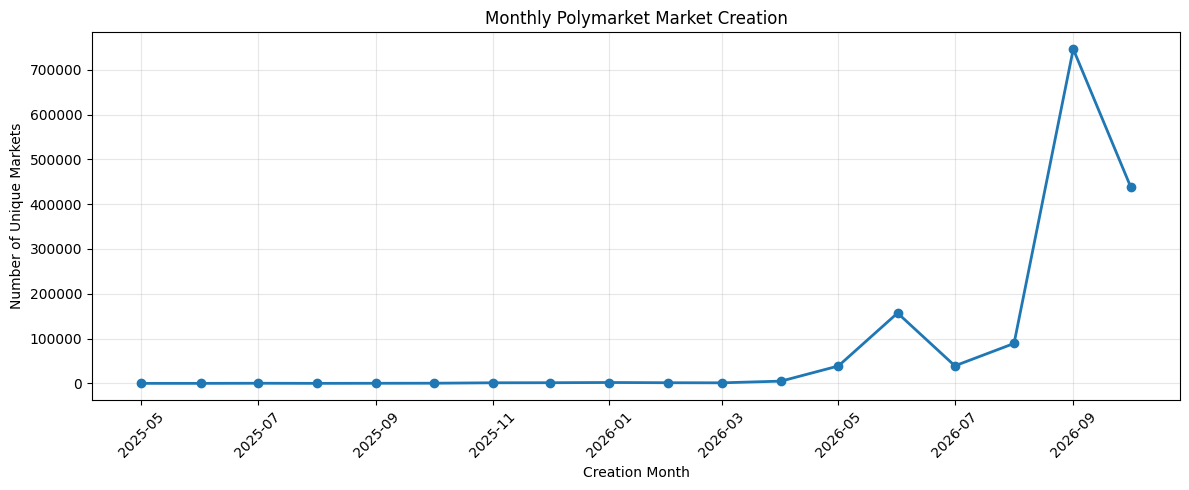

,month,markets_created
0,2025-05-01 00:00:00+00:00,13
1,2025-06-01 00:00:00+00:00,7
2,2025-07-01 00:00:00+00:00,255
3,2025-08-01 00:00:00+00:00,20
4,2025-09-01 00:00:00+00:00,189
5,2025-10-01 00:00:00+00:00,331
6,2025-11-01 00:00:00+00:00,1270
7,2025-12-01 00:00:00+00:00,1426
8,2026-01-01 00:00:00+00:00,1924
9,2026-02-01 00:00:00+00:00,1410


In [ ]:
# Visualize the number of new market records created each month
import matplotlib.pyplot as plt

monthly_markets = pd.read_sql("""
    SELECT
        DATE_TRUNC('month', created_at) AS month,
        COUNT(DISTINCT condition_id) AS markets_created
    FROM public.markets
    WHERE condition_id IS NOT NULL
    GROUP BY 1
    ORDER BY 1
""", engine)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_markets["month"],
    monthly_markets["markets_created"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Polymarket Market Creation")
plt.xlabel("Creation Month")
plt.ylabel("Number of Unique Markets")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_markets)

Market creation counts increase substantially throughout 2026, with a particularly large spike in September, when approximately 745,000 unique markets were created. Earlier months contain considerably fewer records, while October shows a lower count but represents an incomplete month. Although this pattern suggests a significant increase in market listings within the dataset, differences in historical data coverage and collection practices may contribute to the observed trend.

# Connect to Parquet

In [ ]:
# Download the one-hour Polymarket order book Parquet file
from google.colab import userdata
import requests

url = "https://d1yyqbluk0oz0t.cloudfront.net/events-2026-05-30T21.parquet"

response = requests.get(
    url,
    auth=(
        userdata.get("PM_CF_USER"),
        userdata.get("PM_CF_PASSWORD")
    ),
    stream=True,
    timeout=120
)

response.raise_for_status()

with open("events.parquet", "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Parquet file downloaded successfully!")

Parquet file downloaded successfully!


In [ ]:
# Inspect the Parquet schema and count observations, markets, and tokens
import duckdb

con = duckdb.connect()

print("PARQUET SCHEMA")
display(con.execute("""
    DESCRIBE SELECT * FROM read_parquet('events.parquet')
""").df())

print("\nDATASET OVERVIEW")
overview = con.execute("""
    SELECT
        COUNT(*) AS total_observations,
        COUNT(DISTINCT market) AS unique_markets,
        COUNT(DISTINCT asset_id) AS unique_tokens,
        MIN(ts_ms) AS earliest_timestamp,
        MAX(ts_ms) AS latest_timestamp
    FROM read_parquet('events.parquet')
""").df()

display(overview)

PARQUET SCHEMA


,column_name,column_type,null,key,default,extra
0,ts_ms,BIGINT,YES,None,None,None
1,asset_id,VARCHAR,YES,None,None,None
2,market,VARCHAR,YES,None,None,None
3,side,VARCHAR,YES,None,None,None
4,price,DOUBLE,YES,None,None,None
5,size,DOUBLE,YES,None,None,None



DATASET OVERVIEW


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_observations,unique_markets,unique_tokens,earliest_timestamp,latest_timestamp
0,20985641,1813,3491,1780174800002,1780178399998


The Parquet dataset contains approximately 20.99 million order book observations across 1,813 unique markets and 3,491 outcome tokens during a one-hour period on May 30, 2026. The number of tokens is slightly below the expected two per market, suggesting that not every market has observations for both outcomes. Because the dataset captures only one hour, its activity patterns may not represent broader Polymarket trading behavior.

In [ ]:
# Check missing values, zero sizes, and BUY/SELL observations in the Parquet data
orderbook_quality = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE ts_ms IS NULL) AS missing_timestamp,
        COUNT(*) FILTER (WHERE market IS NULL) AS missing_market,
        COUNT(*) FILTER (WHERE asset_id IS NULL) AS missing_token,
        COUNT(*) FILTER (WHERE side IS NULL) AS missing_side,
        COUNT(*) FILTER (WHERE price IS NULL) AS missing_price,
        COUNT(*) FILTER (WHERE size IS NULL) AS missing_size,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size,
        COUNT(*) FILTER (WHERE side = 'BUY') AS buy_rows,
        COUNT(*) FILTER (WHERE side = 'SELL') AS sell_rows
    FROM read_parquet('events.parquet')
""").df()

display(orderbook_quality)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,missing_timestamp,missing_market,missing_token,missing_side,missing_price,missing_size,zero_size,buy_rows,sell_rows
0,20985641,0,0,0,0,0,0,3573986,10495153,10490488


All 20.99 million order book observations have complete values across the six recorded fields. BUY and SELL observations are nearly evenly distributed, while approximately 17.0% of records have a size of zero. These zero-size records may reflect order book updates or other feed behavior, so their meaning should be investigated before excluding them from analysis.

In [ ]:
# Measure how order book observations are distributed across markets
market_activity = con.execute("""
    SELECT
        market,
        COUNT(*) AS observation_count,
        COUNT(DISTINCT asset_id) AS token_count,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size_count
    FROM read_parquet('events.parquet')
    GROUP BY market
    ORDER BY observation_count DESC
""").df()

total_observations = market_activity["observation_count"].sum()

print("Total markets:", len(market_activity))
print("Median observations per market:", market_activity["observation_count"].median())
print("Mean observations per market:", round(market_activity["observation_count"].mean(), 1))

for pct in [1, 5, 10]:
    n = max(1, round(len(market_activity) * pct / 100))
    share = market_activity.head(n)["observation_count"].sum() / total_observations
    print(f"Top {pct}% of markets account for {share:.1%} of observations")

print("\nTop 10 most observed markets:")
display(market_activity.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total markets: 1813
Median observations per market: 2840.0
Mean observations per market: 11575.1
Top 1% of markets account for 26.9% of observations
Top 5% of markets account for 51.3% of observations
Top 10% of markets account for 64.3% of observations

Top 10 most observed markets:


,market,observation_count,token_count,zero_size_count
0,0x3ea5caf58c3bc1f3f8a235e0a539b23488d105f4fb29...,864096,2,52444
1,0xe41ca885d956858e7e87ad83e0c45ff38caf66fc51d9...,490552,2,48072
2,0x27a8ca0b7bdb05c3cea73c9f5365cd0d90bcf00cf552...,482664,2,49420
3,0x51a7c8afb7a0e09b8b47643171d90f400de23a176c4e...,383334,2,108018
4,0x6ce47c4770977e18cc914527ff4156b251d4c663ac34...,337480,2,18026
5,0xd9fb1184af0064e5e34b129f5b79afa5a17b7e32f295...,308334,2,560
6,0x41473424b15ba3f7b6afdf9be34d31da882ce3f55f2a...,291044,2,19196
7,0xf9b7c52816c93754b84b6208025a38639501f53485ed...,262516,2,36276
8,0x2aca3e47d21f7a89c713a1bc36d243013f9fb508df2d...,260376,2,26820
9,0xf4c74ed4324274cd868f9583f2c61bd94a444aa3af3c...,258804,2,126048


### Order Book Activity Concentration

Order book observations are highly concentrated among a relatively small number of markets. The top 1% of markets account for 26.9% of observations, while the top 5% and 10% account for 51.3% and 64.3%, respectively. The mean observation count (11,575) is substantially higher than the median (2,840), indicating a right-skewed distribution in which a small number of markets dominate recorded order book activity. These counts reflect order book records rather than executed trades.

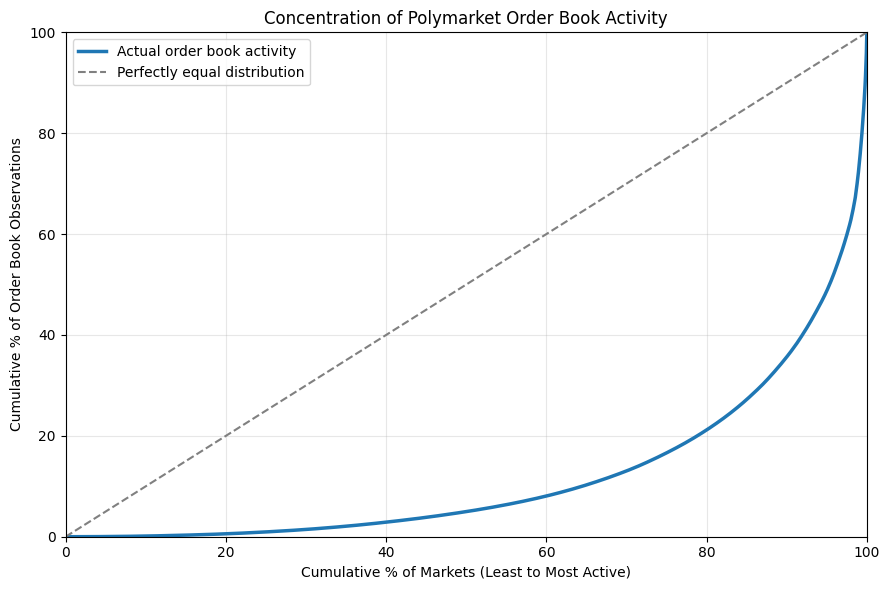

In [ ]:
# Visualize the concentration of order book observations across markets
import numpy as np
import matplotlib.pyplot as plt

counts = np.sort(market_activity["observation_count"].to_numpy())

cumulative_markets = np.linspace(0, 100, len(counts) + 1)
cumulative_activity = np.insert(np.cumsum(counts) / counts.sum() * 100, 0, 0)

plt.figure(figsize=(9, 6))

plt.plot(
    cumulative_markets,
    cumulative_activity,
    linewidth=2.5,
    label="Actual order book activity"
)

plt.plot(
    [0, 100],
    [0, 100],
    "--",
    color="gray",
    label="Perfectly equal distribution"
)

plt.xlabel("Cumulative % of Markets (Least to Most Active)")
plt.ylabel("Cumulative % of Order Book Observations")
plt.title("Concentration of Polymarket Order Book Activity")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The Lorenz curve visualizes how unevenly order book observations are distributed across markets. The diagonal reference line represents a perfectly equal distribution, while deviations below this line indicate concentration. Our analysis shows that the top 5% of markets account for 51.3% of all observations, demonstrating that recorded order book activity is heavily concentrated in a relatively small subset of markets.

In [ ]:
# Measure cumulative trading volume concentration among markets with recorded volume
volume_concentration = pd.read_sql("""
    WITH unique_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            volume_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        volume_clob
    FROM unique_markets
    WHERE volume_clob IS NOT NULL
""", engine)

volumes = volume_concentration["volume_clob"].astype(float).sort_values(ascending=False)

print("Markets with recorded volume:", len(volumes))
print("Markets with positive volume:", (volumes > 0).sum())
print("Median volume: $", round(volumes.median(), 2))
print("Mean volume: $", round(volumes.mean(), 2))
print("Total recorded volume: $", round(volumes.sum(), 2))

for pct in [1, 5, 10]:
    n = max(1, round(len(volumes) * pct / 100))
    share = volumes.head(n).sum() / volumes.sum()
    print(f"Top {pct}% of markets account for {share:.1%} of recorded volume")

cumulative_share = volumes.cumsum() / volumes.sum()
markets_for_80 = (cumulative_share < 0.80).sum() + 1

print(
    f"Percentage of markets accounting for 80% of volume: "
    f"{markets_for_80 / len(volumes):.1%}"
)

Markets with recorded volume: 246417
Markets with positive volume: 184560
Median volume: $ 120.0
Mean volume: $ 50450.83
Total recorded volume: $ 12431941927.63
Top 1% of markets account for 91.9% of recorded volume
Top 5% of markets account for 98.0% of recorded volume
Top 10% of markets account for 99.1% of recorded volume
Percentage of markets accounting for 80% of volume: 0.2%


Cumulative trading volume is extremely concentrated among markets with recorded volume. The top 1% of markets account for approximately 91.9% of total recorded volume, while just 0.2% account for approximately 80%. The mean market volume (50,451) is substantially higher than the median ($120), reflecting a highly right-skewed distribution dominated by a small number of markets. These results apply only to markets with nonmissing volume data and should be interpreted cautiously given the dataset's substantial missingness.

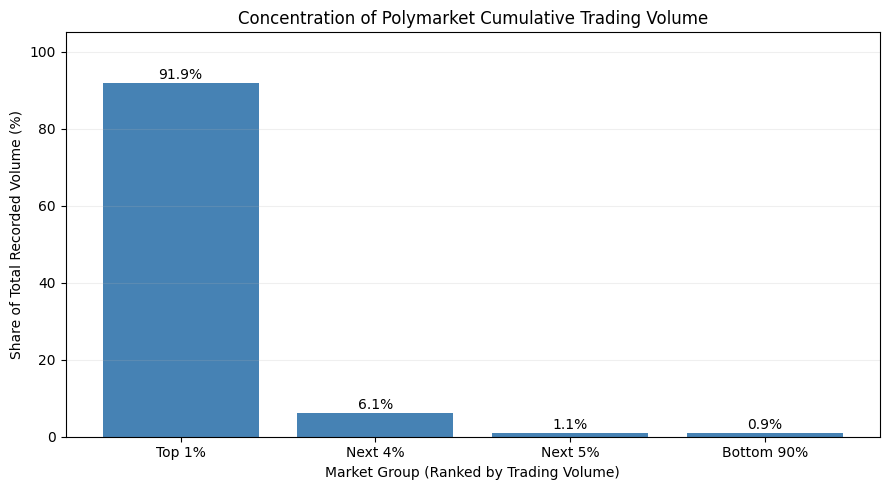

In [ ]:
# Visualize the share of cumulative volume held by different market groups
import matplotlib.pyplot as plt
import numpy as np

n = len(volumes)
ranked_volumes = volumes.sort_values(ascending=False).to_numpy()

cutoffs = [
    0,
    max(1, round(n * 0.01)),
    max(1, round(n * 0.05)),
    max(1, round(n * 0.10)),
    n
]

labels = [
    "Top 1%",
    "Next 4%",
    "Next 5%",
    "Bottom 90%"
]

shares = [
    ranked_volumes[cutoffs[i]:cutoffs[i+1]].sum()
    / ranked_volumes.sum() * 100
    for i in range(4)
]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, shares, color="steelblue")

for bar, share in zip(bars, shares):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        share + 1,
        f"{share:.1f}%",
        ha="center"
    )

plt.title("Concentration of Polymarket Cumulative Trading Volume")
plt.xlabel("Market Group (Ranked by Trading Volume)")
plt.ylabel("Share of Total Recorded Volume (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Trading volume is highly concentrated among a small percentage of markets. The top 1% account for 91.9% of recorded cumulative volume, leaving only 8.1% distributed across the remaining 99% of markets. This substantial imbalance suggests that aggregate Polymarket trading volume is dominated by a relatively small number of contracts.

In [ ]:
# Identify the 20 highest-volume markets and their associated events
top_markets = pd.read_sql("""
    WITH unique_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            title,
            event_slug,
            volume_clob,
            liquidity_clob,
            created_at,
            end_date
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        title,
        event_slug,
        ROUND(volume_clob, 2) AS volume,
        ROUND(liquidity_clob, 2) AS liquidity,
        created_at,
        end_date
    FROM unique_markets
    WHERE volume_clob IS NOT NULL
    ORDER BY volume_clob DESC
    LIMIT 20
""", engine)

display(top_markets)

,title,event_slug,volume,liquidity,created_at,end_date
0,Will Argentina win the 2026 FIFA World Cup?,world-cup-winner,1.742470e+08,8644307.16,2025-07-02 16:54:43.302408+00:00,2026-07-20 00:00:00+00:00
1,Will Egypt win the 2026 FIFA World Cup?,world-cup-winner,1.585808e+08,3410523.93,2025-07-02 16:55:00.390170+00:00,2026-07-20 00:00:00+00:00
2,Will Morocco win the 2026 FIFA World Cup?,world-cup-winner,1.522488e+08,3287518.31,2025-07-02 16:54:57.522078+00:00,2026-07-20 00:00:00+00:00
3,Will Spain win the 2026 FIFA World Cup?,world-cup-winner,1.468545e+08,7839532.08,2025-07-02 16:54:40.860413+00:00,2026-07-20 00:00:00+00:00
4,Will USA win the 2026 FIFA World Cup?,world-cup-winner,1.424577e+08,4708323.19,2025-07-02 16:54:46.301056+00:00,2026-07-20 00:00:00+00:00
5,Will Mexico win the 2026 FIFA World Cup?,world-cup-winner,1.378042e+08,2938587.18,2025-07-02 16:54:47.399042+00:00,2026-07-20 00:00:00+00:00
6,Will Norway win the 2026 FIFA World Cup?,world-cup-winner,1.372862e+08,1323993.65,2025-07-02 16:54:50.383881+00:00,2026-07-20 00:00:00+00:00
7,Will Switzerland win the 2026 FIFA World Cup?,world-cup-winner,1.328352e+08,11463514.63,2025-07-02 16:55:03.947467+00:00,2026-07-20 00:00:00+00:00
8,Will France win the 2026 FIFA World Cup?,world-cup-winner,1.324355e+08,4835363.67,2025-07-02 16:54:42.081862+00:00,2026-07-20 00:00:00+00:00
9,Will Belgium win the 2026 FIFA World Cup?,world-cup-winner,1.292678e+08,5232684.97,2025-07-02 16:54:47.961968+00:00,2026-07-20 00:00:00+00:00


All 20 markets with the highest recorded cumulative trading volume belong to the 2026 FIFA World Cup winner event, with individual market volumes ranging from approximately 97 million to $174 million. This indicates that a single event can generate numerous high-volume contracts, contributing substantially to market-level concentration. The finding motivates further analysis at the event level to determine whether recorded volume is concentrated across a small number of underlying events rather than independent markets.

In [ ]:
# Aggregate recorded market volume by event to identify the largest events
event_volume = pd.read_sql("""
    WITH unique_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            event_slug,
            volume_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        event_slug,
        COUNT(*) AS market_count,
        ROUND(SUM(volume_clob), 2) AS total_recorded_volume,
        ROUND(MAX(volume_clob), 2) AS largest_market_volume
    FROM unique_markets
    WHERE volume_clob IS NOT NULL
      AND event_slug IS NOT NULL
    GROUP BY event_slug
    ORDER BY total_recorded_volume DESC
    LIMIT 20
""", engine)

display(event_volume)

,event_slug,market_count,total_recorded_volume,largest_market_volume
0,world-cup-winner,48,4.312675e+09,1.742470e+08
1,democratic-presidential-nominee-2028,51,1.239303e+09,5.443043e+07
2,republican-presidential-nominee-2028,42,6.906045e+08,4.438765e+07
3,presidential-election-winner-2028,52,6.575408e+08,5.118646e+07
4,us-x-iran-permanent-peace-deal-by,8,2.174888e+08,7.767710e+07
5,next-prime-minister-of-ethiopia,8,2.001269e+08,5.593358e+07
6,2026-f1-drivers-champion,22,1.952530e+08,1.289778e+07
7,brazil-presidential-election,19,1.451205e+08,2.246476e+07
8,fed-decision-in-june-825,5,1.428366e+08,4.305591e+07
9,next-french-presidential-election,41,1.219094e+08,6.214264e+06


Aggregating cumulative market volume by event reveals substantial concentration among major sports and political events. The 2026 FIFA World Cup winner event leads with approximately $4.31 billion in summed reported volume across 48 markets, equivalent to roughly 34.7% of the previously calculated total recorded market volume. The four largest events collectively account for approximately 55.5% of that total. These findings suggest that events containing multiple related contracts play an important role in market-level volume concentration, although summed contract volumes should not necessarily be interpreted as unique dollars traded.

In [ ]:
# Calculate concentration of recorded volume across all events
event_concentration = pd.read_sql("""
    WITH unique_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            event_slug,
            volume_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        event_slug,
        COUNT(*) AS market_count,
        SUM(volume_clob) AS event_volume
    FROM unique_markets
    WHERE volume_clob IS NOT NULL
      AND event_slug IS NOT NULL
    GROUP BY event_slug
""", engine)

event_volumes = (
    event_concentration["event_volume"]
    .astype(float)
    .sort_values(ascending=False)
)

print("Events with recorded volume:", len(event_volumes))
print("Median event volume: $", round(event_volumes.median(), 2))
print("Mean event volume: $", round(event_volumes.mean(), 2))
print("Total event-level summed volume: $", round(event_volumes.sum(), 2))

for pct in [1, 5, 10]:
    n = max(1, round(len(event_volumes) * pct / 100))
    share = event_volumes.head(n).sum() / event_volumes.sum()
    print(f"Top {pct}% of events account for {share:.1%} of recorded volume")

print(
    "Share of volume from largest event:",
    f"{event_volumes.iloc[0] / event_volumes.sum():.1%}"
)

Events with recorded volume: 76683
Median event volume: $ 274.44
Mean event volume: $ 162121.82
Total event-level summed volume: $ 12431987359.89
Top 1% of events account for 93.1% of recorded volume
Top 5% of events account for 98.0% of recorded volume
Top 10% of events account for 99.0% of recorded volume
Share of volume from largest event: 34.7%


In [ ]:
# Recalculate event-level volume concentration after excluding the largest event
remaining_events = event_concentration[
    event_concentration["event_slug"] != "world-cup-winner"
].copy()

remaining_volumes = (
    remaining_events["event_volume"]
    .astype(float)
    .sort_values(ascending=False)
)

print("Events remaining:", len(remaining_volumes))
print("Total volume excluding World Cup: $", round(remaining_volumes.sum(), 2))

for pct in [1, 5, 10]:
    n = max(1, round(len(remaining_volumes) * pct / 100))
    share = remaining_volumes.head(n).sum() / remaining_volumes.sum()
    print(f"Top {pct}% of remaining events account for {share:.1%} of volume")

print(
    "Largest remaining event:",
    remaining_events.loc[
        remaining_events["event_volume"].astype(float).idxmax(),
        "event_slug"
    ]
)

Events remaining: 76682
Total volume excluding World Cup: $ 8119311910.04
Top 1% of remaining events account for 89.4% of volume
Top 5% of remaining events account for 96.9% of volume
Top 10% of remaining events account for 98.5% of volume
Largest remaining event: democratic-presidential-nominee-2028


After excluding the 2026 FIFA World Cup winner event, cumulative trading volume remains highly concentrated. The top 1% of remaining events account for 89.4% of recorded volume, compared with 93.1% when all events are included. Although the largest event contributes substantially to the overall distribution, the persistence of concentration indicates that the observed pattern is not driven by a single outlier.

In [ ]:
# Summarize liquidity and volume availability across unique markets
liquidity_summary = pd.read_sql("""
    WITH unique_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            volume_clob,
            liquidity_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        COUNT(*) AS total_markets,
        COUNT(liquidity_clob) AS markets_with_liquidity,
        COUNT(*) FILTER (WHERE liquidity_clob = 0) AS zero_liquidity,
        COUNT(*) FILTER (WHERE liquidity_clob > 0) AS positive_liquidity,
        COUNT(*) FILTER (
            WHERE volume_clob IS NOT NULL
              AND liquidity_clob IS NOT NULL
        ) AS markets_with_both,
        ROUND(AVG(liquidity_clob), 2) AS mean_liquidity,
        ROUND(
            PERCENTILE_CONT(0.5)
            WITHIN GROUP (ORDER BY liquidity_clob)::numeric,
            2
        ) AS median_liquidity,
        ROUND(MAX(liquidity_clob), 2) AS max_liquidity
    FROM unique_markets
""", engine)

display(liquidity_summary)

,total_markets,markets_with_liquidity,zero_liquidity,positive_liquidity,markets_with_both,mean_liquidity,median_liquidity,max_liquidity
0,1524180,1373000,62034,1310966,244810,5204.38,30.5,33446233.82


Liquidity Distribution and Data Availability

Approximately 90.1% of markets have recorded liquidity values, substantially higher than the availability of cumulative trading volume. The median recorded liquidity is only 30.50, compared with a mean of 5,204.38, indicating a strongly right-skewed distribution influenced by markets with unusually high liquidity. The maximum recorded liquidity exceeds 33 million. Only approximately 245,000 markets contain both volume and liquidity values, which limits the sample available for analyzing their relationship.

# Do markets with higher cumulative trading volume also tend to have higher recorded liquidity?

Markets with positive volume and liquidity: 182777
Spearman correlation: 0.407


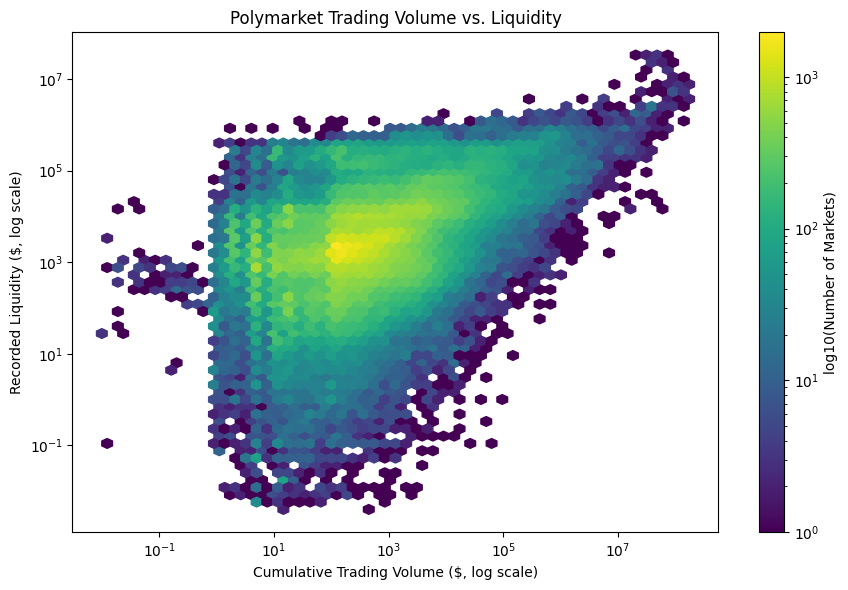

In [ ]:
# Explore the relationship between cumulative trading volume and recorded liquidity
import numpy as np
import matplotlib.pyplot as plt

volume_liquidity = pd.read_sql("""
    SELECT DISTINCT ON (condition_id)
        condition_id,
        volume_clob::float AS volume,
        liquidity_clob::float AS liquidity
    FROM public.markets
    WHERE condition_id IS NOT NULL
      AND volume_clob > 0
      AND liquidity_clob > 0
    ORDER BY condition_id, synced_at DESC NULLS LAST
""", engine)

spearman_corr = volume_liquidity["volume"].corr(
    volume_liquidity["liquidity"],
    method="spearman"
)

print("Markets with positive volume and liquidity:", len(volume_liquidity))
print(f"Spearman correlation: {spearman_corr:.3f}")

plt.figure(figsize=(9, 6))

plt.hexbin(
    volume_liquidity["volume"],
    volume_liquidity["liquidity"],
    xscale="log",
    yscale="log",
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="log10(Number of Markets)")
plt.xlabel("Cumulative Trading Volume ($, log scale)")
plt.ylabel("Recorded Liquidity ($, log scale)")
plt.title("Polymarket Trading Volume vs. Liquidity")
plt.tight_layout()
plt.show()

Among 182,777 markets with positive recorded volume and liquidity, Spearman correlation is 0.407, indicating a moderate positive association. Markets with higher cumulative trading volume generally tend to have higher recorded liquidity, although substantial variation exists among markets with similar volume levels. The logarithmic hexbin plot also highlights the wide range of market sizes and the relatively small number of extreme observations. These findings are descriptive and do not establish a causal relationship.

# results from market data

volume is extremely concentrated, liquidity is strongly right-skewed, and volume and liquidity have a moderate positive association.


# looking into some important markets

In [ ]:
# Compare trading volume and liquidity across six major Polymarket events
event_comparison = pd.read_sql("""
    WITH latest_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            event_slug,
            volume_clob,
            liquidity_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        event_slug,
        COUNT(*) AS total_markets,
        COUNT(volume_clob) AS markets_with_volume,
        ROUND(SUM(volume_clob), 2) AS total_volume,
        ROUND(AVG(volume_clob), 2) AS avg_market_volume,
        ROUND(
            PERCENTILE_CONT(0.5)
            WITHIN GROUP (ORDER BY volume_clob)::numeric, 2
        ) AS median_market_volume,
        ROUND(SUM(liquidity_clob), 2) AS total_liquidity,
        ROUND(AVG(liquidity_clob), 2) AS avg_market_liquidity
    FROM latest_markets
    WHERE event_slug IN (
        'world-cup-winner',
        'democratic-presidential-nominee-2028',
        'republican-presidential-nominee-2028',
        'presidential-election-winner-2028',
        'us-x-iran-permanent-peace-deal-by',
        'venezuela-leader-end-of-2026'
    )
    GROUP BY event_slug
    ORDER BY total_volume DESC
""", engine)

display(event_comparison)

,event_slug,total_markets,markets_with_volume,total_volume,avg_market_volume,median_market_volume,total_liquidity,avg_market_liquidity
0,world-cup-winner,48,48,4.312675e+09,89847405.21,88751380.16,5.743863e+08,11966380.97
1,democratic-presidential-nominee-2028,51,51,1.239303e+09,24300057.08,22871203.94,7.812978e+07,1531956.50
2,republican-presidential-nominee-2028,42,42,6.906045e+08,16442963.19,15701142.40,5.674937e+07,1351175.44
3,presidential-election-winner-2028,52,52,6.575408e+08,12645014.87,9574194.62,5.919847e+07,1138432.16
4,us-x-iran-permanent-peace-deal-by,8,8,2.174888e+08,27186105.26,15332354.54,3.327647e+06,415955.92
5,venezuela-leader-end-of-2026,16,16,9.262532e+07,5789082.47,1689967.95,1.696279e+06,106017.42


Comparing six major Polymarket events reveals substantial differences in cumulative trading volume, recorded liquidity, and the distribution of activity across individual markets. The 2026 FIFA World Cup winner event has the highest total recorded volume at approximately 4.31 billion across 48 markets, with an average market volume of 89.85 million and a median of 88.75 million. It also has the highest total recorded liquidity at approximately 574.39 million, averaging 11.97 million per market. The relatively small difference between its mean and median trading volume suggests that volume may be more evenly distributed across its individual contracts than in some of the other events examined.

In comparison, the 2028 Democratic presidential nominee event contains 51 markets but has a considerably lower total recorded volume of 1.24 billion, with an average of 24.30 million and a median of 22.87 million per market. Its total recorded liquidity is approximately 78.13 million, averaging 1.53 million per market. Despite having three more markets than the World Cup event, its total trading volume is approximately 3.5 times smaller, while its average liquidity is nearly 7.8 times lower. The 2028 Republican presidential nominee event records approximately $690.60 million in total volume across 42 markets, while the 2028 presidential election winner event records 657.54 million across 52 markets. Their average market volumes are approximately 16.44 million and 12.65 million, respectively, illustrating differences in reported activity even among major political events.

The geopolitical events show somewhat different patterns. The US–Iran permanent peace deal event contains only 8 markets but records approximately 217.49 million in total trading volume, averaging 27.19 million per market. However, its median market volume is considerably lower at 15.33 million, suggesting that some individual contracts contribute disproportionately to the event's total volume. Its average recorded liquidity is approximately 415,956, substantially below that of the major sports and US election events despite its relatively high average trading volume. Similarly, the Venezuela leadership event contains 16 markets with approximately $92.63 million in total recorded volume. Its average market volume is 5.79 million, compared with a median of only 1.69 million, suggesting an uneven distribution of volume across contracts. This event also has the lowest average recorded liquidity among the six events, at approximately 106,017 per market.

Overall, these comparisons highlight that event-level trading volume is influenced by more than the number of markets associated with an event. The World Cup winner event exhibits exceptionally high volume and liquidity across many individual contracts, while the geopolitical events show larger differences between average and median market volume. Additionally, the US–Iran event demonstrates that relatively high cumulative trading volume does not necessarily correspond to proportionally high recorded liquidity. These findings suggest meaningful differences in the structure and distribution of reported market activity across the selected events. However, because trading volume is cumulative and liquidity represents recorded metadata values, these comparisons are descriptive and should not be interpreted as evidence of differences in trading efficiency or trader behavior.

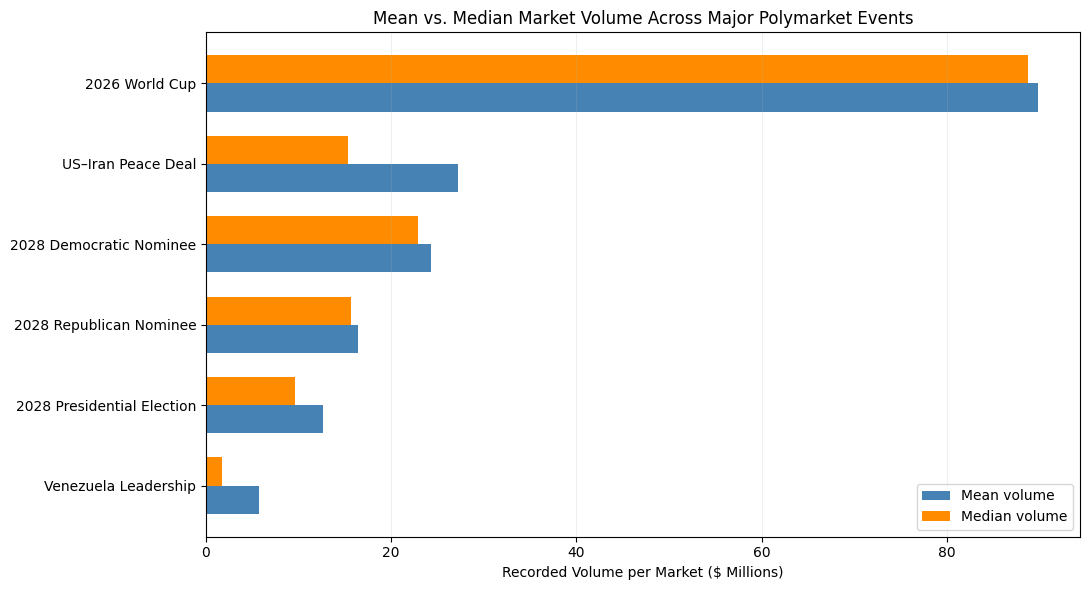

In [ ]:
# Compare average and median trading volume per market across major events
import matplotlib.pyplot as plt
import numpy as np

event_labels = {
    "world-cup-winner": "2026 World Cup",
    "democratic-presidential-nominee-2028": "2028 Democratic Nominee",
    "republican-presidential-nominee-2028": "2028 Republican Nominee",
    "presidential-election-winner-2028": "2028 Presidential Election",
    "us-x-iran-permanent-peace-deal-by": "US–Iran Peace Deal",
    "venezuela-leader-end-of-2026": "Venezuela Leadership"
}

df = event_comparison.copy()
df["event_name"] = df["event_slug"].map(event_labels)

df = df.sort_values("avg_market_volume")

y = np.arange(len(df))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    y - height / 2,
    df["avg_market_volume"] / 1e6,
    height,
    label="Mean volume",
    color="steelblue"
)

ax.barh(
    y + height / 2,
    df["median_market_volume"] / 1e6,
    height,
    label="Median volume",
    color="darkorange"
)

ax.set_yticks(y)
ax.set_yticklabels(df["event_name"])
ax.set_xlabel("Recorded Volume per Market ($ Millions)")
ax.set_title("Mean vs. Median Market Volume Across Major Polymarket Events")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

The grouped bar chart compares mean and median cumulative trading volume per market across six major Polymarket events. The World Cup winner event has substantially higher typical market volume than the other events, with both its mean and median near $90 million. The US–Iran peace deal and Venezuela leadership events show larger gaps between their mean and median volumes, suggesting that higher-volume contracts may have a greater influence on their event-level averages. These differences highlight variation in how reported trading volume is distributed across contracts within major events.

In [ ]:
# Compare how much event volume is concentrated in the three largest contracts
event_market_volumes = pd.read_sql("""
    WITH latest_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id,
            event_slug,
            title,
            volume_clob
        FROM public.markets
        WHERE condition_id IS NOT NULL
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT
        event_slug,
        title,
        volume_clob::float AS volume
    FROM latest_markets
    WHERE event_slug IN (
        'world-cup-winner',
        'democratic-presidential-nominee-2028',
        'republican-presidential-nominee-2028',
        'presidential-election-winner-2028',
        'us-x-iran-permanent-peace-deal-by',
        'venezuela-leader-end-of-2026'
    )
      AND volume_clob IS NOT NULL
""", engine)

event_market_volumes = event_market_volumes.sort_values(
    ["event_slug", "volume"],
    ascending=[True, False]
)

event_market_volumes["rank"] = (
    event_market_volumes.groupby("event_slug").cumcount() + 1
)

concentration = event_market_volumes.groupby("event_slug").apply(
    lambda group: pd.Series({
        "market_count": len(group),
        "top_1_share": group.head(1)["volume"].sum() / group["volume"].sum() * 100,
        "top_3_share": group.head(3)["volume"].sum() / group["volume"].sum() * 100
    }),
    include_groups=False
).reset_index()

display(concentration.round(2))

,event_slug,market_count,top_1_share,top_3_share
0,democratic-presidential-nominee-2028,51.0,4.39,12.70
1,presidential-election-winner-2028,52.0,7.78,19.64
2,republican-presidential-nominee-2028,42.0,6.43,17.94
3,us-x-iran-permanent-peace-deal-by,8.0,35.72,81.00
4,venezuela-leader-end-of-2026,16.0,35.24,72.61
5,world-cup-winner,48.0,4.04,11.25


Trading volume concentration differs substantially across the six selected Polymarket events. The 2026 World Cup winner event exhibits a relatively distributed volume structure, with its largest market accounting for only 4.04% of total event volume and its three largest markets accounting for 11.25% across 48 markets. Similarly, the 2028 Democratic presidential nominee event has 51 markets, with its largest contract contributing 4.39% and its top three contributing 12.70% of total volume. The Republican presidential nominee and presidential election winner events exhibit somewhat greater concentration, with top-three shares of 17.94% and 19.64%, respectively.

In contrast, the geopolitical events exhibit substantially higher concentration among their largest contracts. For the US–Iran permanent peace deal event, the largest market accounts for 35.72% of total volume, while the top three markets account for 81.00% across just eight markets. Similarly, the Venezuela leadership event has 16 markets, with its largest contract contributing 35.24% and its three largest contributing 72.61% of total volume. These findings suggest that recorded volume in the selected geopolitical events is concentrated among a relatively small number of contracts, whereas the World Cup and presidential nominee events exhibit more distributed trading activity.

However, differences in the number of markets must be considered when interpreting these results. Events with fewer contracts will naturally tend to have higher top-three shares, even when volume is distributed evenly. Therefore, these results provide an initial descriptive comparison rather than a fully standardized measure of concentration.

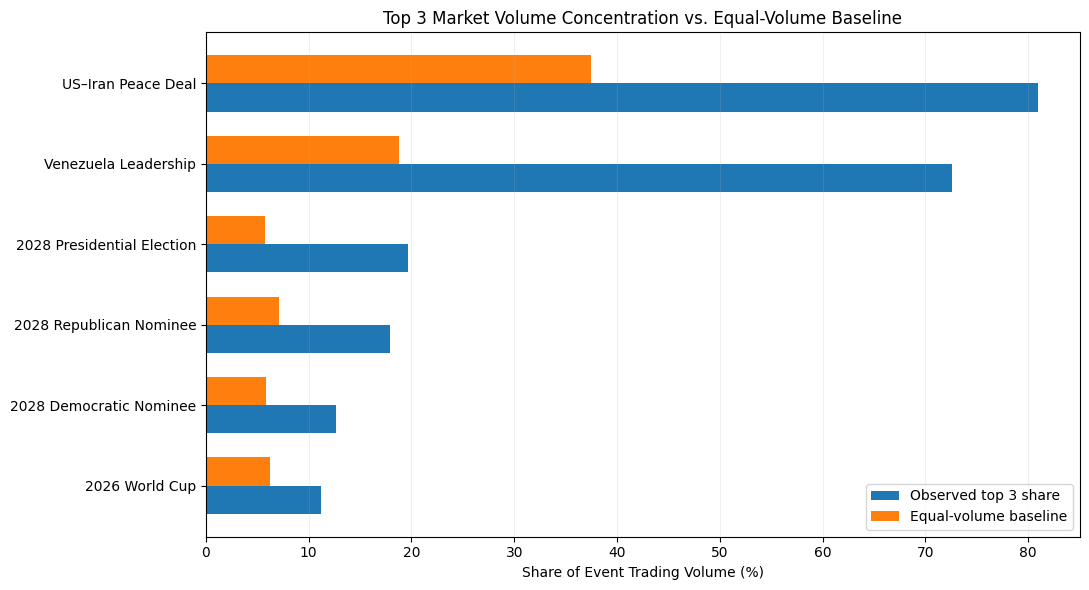

In [ ]:
# Compare observed top-three volume concentration against an equal-volume baseline
import numpy as np
import matplotlib.pyplot as plt

labels = {
    "world-cup-winner": "2026 World Cup",
    "democratic-presidential-nominee-2028": "2028 Democratic Nominee",
    "republican-presidential-nominee-2028": "2028 Republican Nominee",
    "presidential-election-winner-2028": "2028 Presidential Election",
    "us-x-iran-permanent-peace-deal-by": "US–Iran Peace Deal",
    "venezuela-leader-end-of-2026": "Venezuela Leadership"
}

plot_df = concentration.copy()
plot_df["event"] = plot_df["event_slug"].map(labels)
plot_df["equal_share"] = 300 / plot_df["market_count"]
plot_df = plot_df.sort_values("top_3_share")

y = np.arange(len(plot_df))
h = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(y - h/2, plot_df["top_3_share"], h, label="Observed top 3 share")
ax.barh(y + h/2, plot_df["equal_share"], h, label="Equal-volume baseline")

ax.set_yticks(y)
ax.set_yticklabels(plot_df["event"])
ax.set_xlabel("Share of Event Trading Volume (%)")
ax.set_title("Top 3 Market Volume Concentration vs. Equal-Volume Baseline")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

The visualization compares the observed share of trading volume generated by the three largest markets within each event against an equal-volume baseline that accounts for differences in market counts. The 2026 World Cup winner event exhibits relatively low concentration, with its top three markets contributing 11.25% of total event volume, compared with 6.25% under equal distribution. The 2028 Democratic presidential nominee event follows a similar pattern, with an observed top-three share of 12.70%, compared with a baseline of 5.88%.

In contrast, the US–Iran permanent peace deal and Venezuela leadership events exhibit substantially greater absolute concentration. The top three US–Iran contracts account for 81.00% of total volume, compared with a baseline of 37.50%. For Venezuela, the top three contracts contribute 72.61%, compared with an equal-volume baseline of only 18.75%. Relative to their respective baselines, the US–Iran event has approximately 2.16 times the equal-volume concentration, while Venezuela has approximately 3.87 times.

Interestingly, although US–Iran has the highest absolute top-three share, Venezuela exhibits the greatest relative concentration among the six events. The presidential election winner event also shows notable relative concentration, with its top three markets accounting for 19.64% of volume compared with a baseline of 5.77%, or approximately 3.40 times the equal-volume share. Overall, these results suggest that the distribution of recorded trading volume varies considerably across major Polymarket events, with the World Cup exhibiting a more distributed pattern and Venezuela showing particularly strong concentration relative to its number of contracts.

In [ ]:
# Identify the highest-volume contracts in the US–Iran and Venezuela events
selected_events = {
    "us-x-iran-permanent-peace-deal-by": "US–Iran Peace Deal",
    "venezuela-leader-end-of-2026": "Venezuela Leadership"
}

top_contracts = event_market_volumes[
    event_market_volumes["event_slug"].isin(selected_events)
].copy()

top_contracts["event"] = top_contracts["event_slug"].map(selected_events)

top_contracts["volume_share_pct"] = (
    top_contracts["volume"] /
    top_contracts.groupby("event_slug")["volume"].transform("sum") * 100
)

top_contracts["volume_millions"] = top_contracts["volume"] / 1e6

top_contracts = top_contracts.sort_values(
    ["event", "volume"],
    ascending=[True, False]
)

display(
    top_contracts[
        ["event", "title", "volume_millions", "volume_share_pct"]
    ].round(2)
)

,event,title,volume_millions,volume_share_pct
9,US–Iran Peace Deal,"US x Iran permanent peace deal by May 31, 2026?",77.68,35.72
181,US–Iran Peace Deal,"US x Iran permanent peace deal by June 15, 2026?",63.77,29.32
82,US–Iran Peace Deal,"US x Iran permanent peace deal by June 30, 2026?",34.71,15.96
45,US–Iran Peace Deal,"US x Iran permanent peace deal by June 7, 2026?",19.01,8.74
134,US–Iran Peace Deal,"US x Iran permanent peace deal by December 31,...",11.66,5.36
24,US–Iran Peace Deal,"US x Iran permanent peace deal by July 31, 2026?",8.38,3.85
185,US–Iran Peace Deal,"US x Iran permanent peace deal by August 31, 2...",1.61,0.74
3,US–Iran Peace Deal,"US x Iran permanent peace deal by October 31, ...",0.67,0.31
116,Venezuela Leadership,Will Richard Grenell be the leader of Venezuel...,32.64,35.24
114,Venezuela Leadership,Will Frank Donovan be the leader of Venezuela ...,25.80,27.85


Examining individual contracts reveals different patterns of trading volume concentration within the US–Iran permanent peace deal and Venezuela leadership events. For the US–Iran event, trading volume is concentrated in contracts associated with specific deadlines. The May 31, 2026 contract records approximately $77.68 million (35.72%), followed by June 15 at $63.77 million (29.32%) and June 30 at $34.71 million (15.96%). Together, these three contracts account for approximately 81.00% of the event's $217.49 million in total recorded volume. This indicates that cumulative trading activity was substantially greater for certain deadlines than for others.

The Venezuela leadership event exhibits a different structure, with individual contracts corresponding to potential leaders. The Richard Grenell contract records approximately $32.64 million (35.24%), followed by Frank Donovan at $25.80 million (27.85%) and Pete Hegseth at $8.82 million (9.53%). Together, these three contracts account for 72.61% of the event's $92.63 million in total recorded volume. The two largest contracts alone contribute 63.09%, demonstrating that much of the event's recorded trading volume is associated with a small subset of named individuals.

Overall, these findings show that high event-level concentration can arise in markets with different contract structures. In the US–Iran event, the highest-volume contracts are distinguished by their resolution deadlines, whereas the Venezuela event is organized around named individuals. Although both events exhibit concentrated trading activity, the underlying contract characteristics differ. Importantly, these comparisons describe cumulative trading volume and do not establish when trading activity occurred, why particular contracts attracted more volume, or which outcomes traders considered most likely.

## Activity over time

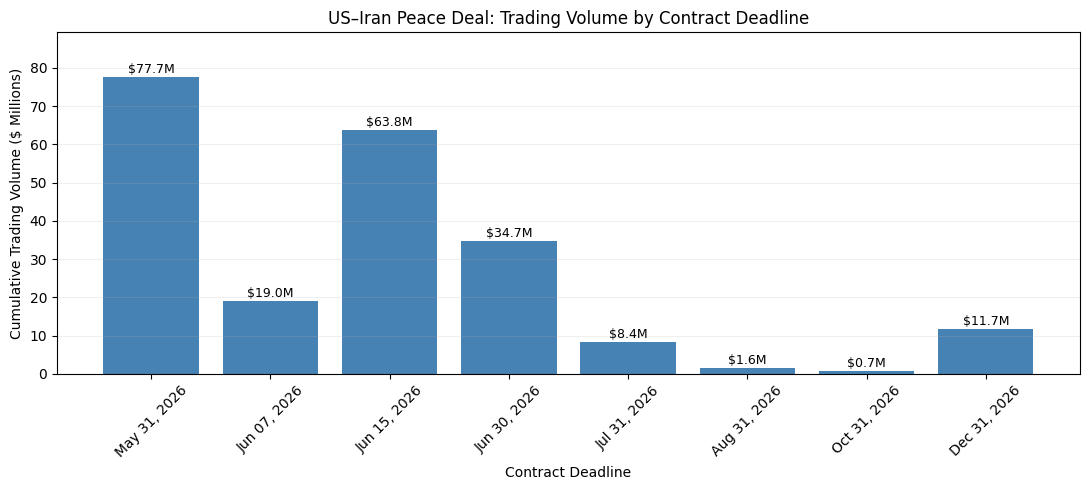

In [ ]:
# Plot US–Iran peace deal contract volumes in chronological order
import pandas as pd
import matplotlib.pyplot as plt

iran_df = event_market_volumes[
    event_market_volumes["event_slug"] == "us-x-iran-permanent-peace-deal-by"
].copy()

iran_df["deadline"] = pd.to_datetime(
    iran_df["title"].str.extract(r"by (.+?)\?")[0],
    errors="coerce"
)

iran_df = iran_df.sort_values("deadline")
iran_df["volume_millions"] = iran_df["volume"] / 1e6

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    iran_df["deadline"].dt.strftime("%b %d, %Y"),
    iran_df["volume_millions"],
    color="steelblue"
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"${bar.get_height():.1f}M",
        ha="center",
        fontsize=9
    )

ax.set_title("US–Iran Peace Deal: Trading Volume by Contract Deadline")
ax.set_xlabel("Contract Deadline")
ax.set_ylabel("Cumulative Trading Volume ($ Millions)")
ax.set_ylim(0, iran_df["volume_millions"].max() * 1.15)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

The visualization examines how cumulative trading volume varies across eight US–Iran permanent peace deal contracts with different resolution deadlines. Trading volume is heavily concentrated among contracts expiring in May and June 2026. The May 31 deadline records the highest volume at approximately $77.68 million, followed by June 15 at $63.77 million and June 30 at $34.71 million. Together, these three contracts account for approximately 81% of the event's total recorded trading volume of $217.49 million.

Although earlier deadlines generally exhibit higher trading volume than later deadlines, the relationship is not strictly decreasing. For example, the June 15 contract records substantially more volume than the earlier June 7 contract, which accumulated approximately $19.01 million. Similarly, trading volume declines to 8.38 million for July 31, 1.61 million for August 31, and 0.67 million for October 31, before increasing to 11.66 million for December 31. This indicates that the distribution of trading activity cannot be explained solely by the chronological ordering of contract deadlines.

Overall, the results demonstrate that cumulative trading volume within this event is concentrated around a small number of specific deadlines, particularly May 31 and June 15. However, because the analysis uses cumulative market-level volume rather than historical transaction data, it cannot determine when trading activity occurred or why particular deadlines attracted more volume. Differences in market creation dates and trading exposure may also influence these comparisons.

# Parquet hourly data

Activity over time: Are order book observations evenly distributed throughout the hour, or are there sudden spikes?



Market activity: Which markets account for the most observations during this hour?



BUY vs. SELL: How do the two sides differ in observation counts, prices, and displayed sizes?



Order sizes and prices: What does the distribution of observed order book levels look like?



Market-level comparisons: Are markets with high cumulative volume also the most active during this particular hour?

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

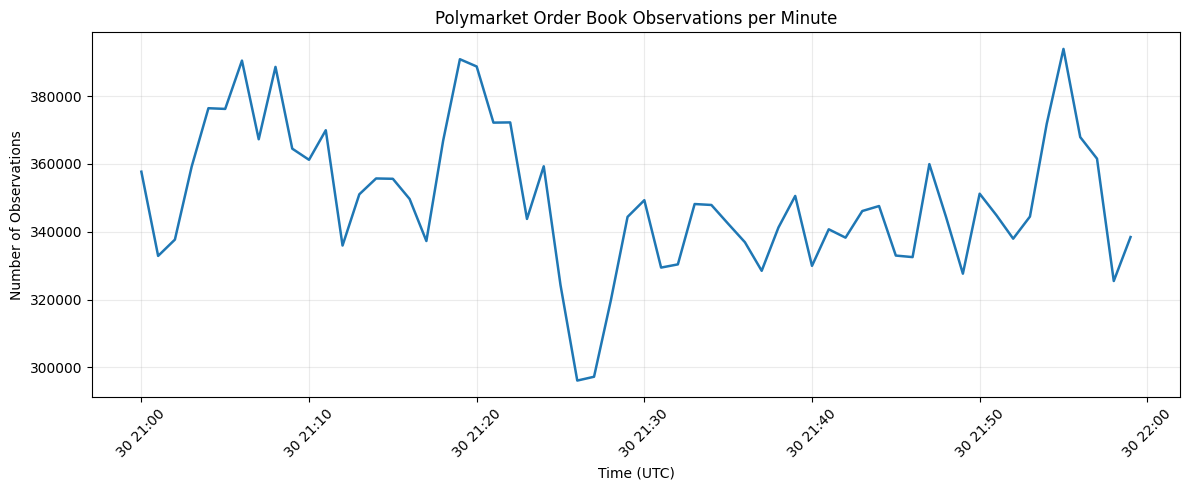

Minutes observed: 60
Average observations per minute: 349,761
Minimum observations per minute: 296,142
Maximum observations per minute: 393,899
Average active markets per minute: 1,480.1


In [ ]:
# Count order book observations per minute during the one-hour window
import matplotlib.pyplot as plt

minute_activity = con.execute("""
    SELECT
        DATE_TRUNC('minute', TO_TIMESTAMP(ts_ms / 1000.0)) AS minute,
        COUNT(*) AS observation_count,
        COUNT(DISTINCT market) AS active_markets
    FROM read_parquet('events.parquet')
    GROUP BY 1
    ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    minute_activity["minute"],
    minute_activity["observation_count"],
    linewidth=1.8
)

ax.set_title("Polymarket Order Book Observations per Minute")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Number of Observations")
ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Minutes observed:", len(minute_activity))
print("Average observations per minute:",
      f'{minute_activity["observation_count"].mean():,.0f}')
print("Minimum observations per minute:",
      f'{minute_activity["observation_count"].min():,}')
print("Maximum observations per minute:",
      f'{minute_activity["observation_count"].max():,}')
print("Average active markets per minute:",
      f'{minute_activity["active_markets"].mean():,.1f}')

The one-minute aggregation of Polymarket order book observations reveals a relatively stable level of recorded activity throughout the one-hour window on May 30, 2026. Most minutes contain approximately 330,000 to 370,000 observations, indicating that the dataset maintains a fairly consistent observation frequency over time. However, several short-term fluctuations are visible, with observation counts approaching 390,000–395,000 around 21:06, 21:19–21:20, and 21:55 UTC.

The most notable decline occurs around 21:25–21:26 UTC, when observation counts fall to approximately 296,000–297,000, before recovering shortly afterward. Although this represents a noticeable deviation from the surrounding minutes, the graph alone cannot determine whether the decline reflects reduced order book activity, changes in the number of observed markets, or variation in data collection. Overall, the results suggest relatively consistent observation frequency across the hour, with several brief periods of elevated or reduced activity.

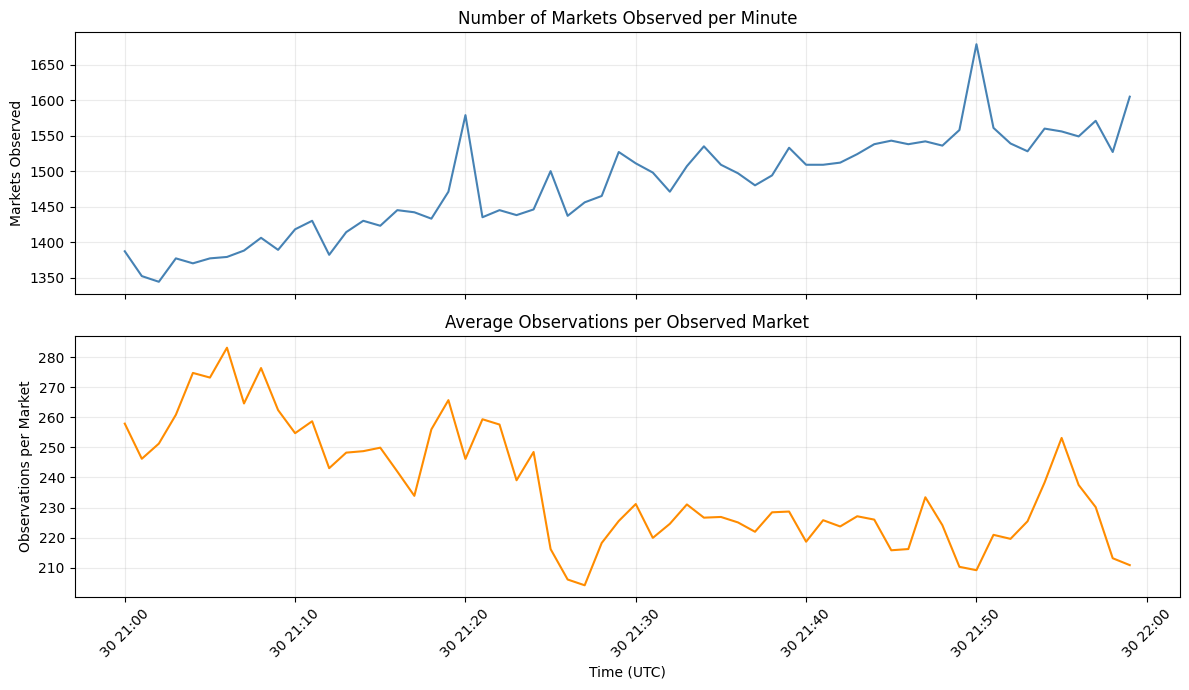

Average markets observed per minute: 1480.1
Minimum markets observed: 1344
Maximum markets observed: 1679


In [ ]:
# Compare the number of observed markets with observations per market each minute
import matplotlib.pyplot as plt

minute_activity["observations_per_market"] = (
    minute_activity["observation_count"] /
    minute_activity["active_markets"]
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    minute_activity["minute"],
    minute_activity["active_markets"],
    color="steelblue"
)
axes[0].set_ylabel("Markets Observed")
axes[0].set_title("Number of Markets Observed per Minute")
axes[0].grid(alpha=0.25)

axes[1].plot(
    minute_activity["minute"],
    minute_activity["observations_per_market"],
    color="darkorange"
)
axes[1].set_ylabel("Observations per Market")
axes[1].set_xlabel("Time (UTC)")
axes[1].set_title("Average Observations per Observed Market")
axes[1].grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average markets observed per minute:",
      round(minute_activity["active_markets"].mean(), 1))
print("Minimum markets observed:",
      minute_activity["active_markets"].min())
print("Maximum markets observed:",
      minute_activity["active_markets"].max())

The hourly order book data reveals contrasting trends in market coverage and observation frequency. The number of distinct markets observed per minute generally increases throughout the hour, rising from approximately 1,350–1,400 markets near 21:00 UTC to around 1,550–1,600 markets toward the end of the observation window. Across the hour, an average of 1,480.1 markets are observed per minute, with a minimum of 1,344 and a maximum of 1,679.

In contrast, the average number of observations per market generally declines over the same period. Early in the hour, markets record approximately 250–280 observations per minute, compared with approximately 210–230 observations per minute later in the hour. This helps explain why the total number of observations per minute remains relatively stable despite the increasing number of observed markets.

The pronounced decline in total observations around 21:25–21:26 UTC appears to be associated primarily with a reduction in observations per market rather than a substantial decrease in the number of markets observed. Overall, these findings suggest that the composition and observation frequency of markets vary throughout the hour. However, the data does not establish whether these changes reflect underlying market activity, data collection behavior, or differences in which markets are represented at different times.

In [ ]:
# Inspect market identifiers before joining hourly observations to Supabase metadata
print("Sample Parquet market identifiers:")
display(
    con.execute("""
        SELECT DISTINCT market
        FROM read_parquet('events.parquet')
        LIMIT 10
    """).df()
)

print("\nSample Supabase condition IDs:")
display(
    pd.read_sql("""
        SELECT condition_id, title, event_slug
        FROM public.markets
        WHERE condition_id IS NOT NULL
        LIMIT 10
    """, engine)
)

Sample Parquet market identifiers:


,market
0,0x5db999fad322cea2914535aae5517060c3f80ad6d8c0...
1,0x51a7c8afb7a0e09b8b47643171d90f400de23a176c4e...
2,0xcef9a8128a2fbb8bdb7aef92145efd707e064b15e151...
3,0xb71f627ef32b3b358419cba028824cebdbc54534780c...
4,0x27a8ca0b7bdb05c3cea73c9f5365cd0d90bcf00cf552...
5,0x90d0f0f57e38136c7ae56743e682c1eb29aa4e9f17fa...
6,0x043726dab442991a3dd7f925a9efff2adff94e7883df...
7,0x645a908b92e9a26af37a35af9556b0fccfe7d094cb2f...
8,0xd9fb1184af0064e5e34b129f5b79afa5a17b7e32f295...
9,0x0a46731134b06c151d4f939bec58e07d784ed50ed214...



Sample Supabase condition IDs:


,condition_id,title,event_slug
0,0xe89eddba22d20b13f81b8cb7a6f22b2595e0b89dfb1d...,Set Handicap: Hunter/Siniakova (-1.5) vs Erran...,wta-doubles-huntsin-errapao-2026-10-17
1,0x577256d1162e7678aff48f3849fbe420ce14372c7935...,Set Handicap: Haverlag/Kubka (-1.5) vs Basilet...,wta-doubles-havekub-basimad-2026-10-17
2,0xde9ec64ccfd586814aa3fc11ad39b9f5fdbf00ff3ce8...,Hunter/Siniakova vs. Errani/Paolini: Total Set...,wta-doubles-huntsin-errapao-2026-10-17
3,0xcfa35d6c4c80a743c646d4a76af7a0f631439a00206a...,Bhosale/Salden vs. Salkova/Siskova: Total Sets...,wta-doubles-bhossal-salksis-2026-10-17
4,0x7dff0ebe15f77f4011d3856b3108e2eff95a355d3480...,Kym vs. Brunold: Set 1 Games O/U 9.5,atp-kym-brunold-2026-10-17
5,0x07e319658f4a89b6bf5edda81d3863dd0c6eaffd9efc...,Set 1 Winner: Jerome Kym vs Mika Brunold,atp-kym-brunold-2026-10-17
6,0x42cc88d6a479792baf4139cfa86c3b732b508653bf6c...,"Almaty Open, Qualification: Completed Match: A...",atp-omarkha-sakamot-2026-10-17
7,0x7aa57f05423252ff934e9e79148a133294cf135bdee0...,"ZCash Up or Down - October 18, 3:10AM-3:15AM ET",zec-updown-5m-1792307400
8,0xa0842454add111dc58277729d2a304f28a9fd79f8a5f...,"Solana Up or Down - October 17, 3:15AM-3:20AM ET",sol-updown-5m-1792221300
9,0x3aa36eb51f13c29d1abc6ad74e3d9931b32f5bdf0158...,"Ethereum Up or Down - October 17, 3:15AM-3:20A...",eth-updown-5m-1792221300


In [ ]:
# Match hourly order book markets to Supabase metadata and identify the most observed markets
market_ids = market_activity["market"].dropna().unique().tolist()

from sqlalchemy import bindparam

query = text("""
    WITH latest_markets AS (
        SELECT DISTINCT ON (condition_id)
            condition_id, title, event_slug, volume_clob, liquidity_clob
        FROM public.markets
        WHERE condition_id IN :market_ids
        ORDER BY condition_id, synced_at DESC NULLS LAST
    )
    SELECT * FROM latest_markets
""").bindparams(bindparam("market_ids", expanding=True))

market_metadata = pd.read_sql(
    query,
    engine,
    params={"market_ids": market_ids}
)

hourly_markets = market_activity.merge(
    market_metadata,
    left_on="market",
    right_on="condition_id",
    how="left"
)

print("Total markets in hourly data:", len(hourly_markets))
print("Markets matched to Supabase:", hourly_markets["title"].notna().sum())
print(
    "Match rate:",
    f'{hourly_markets["title"].notna().mean() * 100:.1f}%'
)

display(
    hourly_markets.nlargest(20, "observation_count")[
        ["title", "event_slug", "observation_count",
         "token_count", "volume_clob", "liquidity_clob"]
    ]
)

Total markets in hourly data: 1813
Markets matched to Supabase: 1813
Match rate: 100.0%


,title,event_slug,observation_count,token_count,volume_clob,liquidity_clob
0,Roland Garros ATP: Jaime Faria vs Frances Tiafoe,atp-faria-tiafoe-2026-05-30,864096,2,4.094937e+04,73919.19000
1,Will Botafogo FR win on 2026-05-30?,bra-bah-bot-2026-05-30,490552,2,3.488459e+05,228606.16041
2,Will EC Bahia win on 2026-05-30?,bra-bah-bot-2026-05-30,482664,2,2.144507e+03,229290.52630
3,Iran closes its airspace by June 30?,iran-closes-its-airspace-by,383334,2,2.241253e+06,35785.42024
4,Roland Garros ATP: Felix Auger-Aliassime vs Br...,atp-augeral-nakashi-2026-05-30,337480,2,9.282137e+05,627489.18181
5,Will China invade Taiwan by end of 2026?,will-china-invade-taiwan-before-2027,308334,2,3.127293e+07,883202.49706
6,Miami Marlins vs. New York Mets,mlb-mia-nym-2026-05-30,291044,2,6.042292e+02,34197.95650
7,ASVEL Lyon-Villeurbanne vs. Cholet,bkfr1-asv-cho-2026-05-30,262516,2,5.493972e+02,15884.04470
8,Kansas City Royals vs. Texas Rangers,mlb-kc-tex-2026-05-30,260376,2,3.675180e+02,23697.07700
9,Counter-Strike: Misa Esports vs ZOTIX (BO3) - ...,cs2-mis-zotix-2026-05-30,258804,2,1.038656e+04,3843.69430


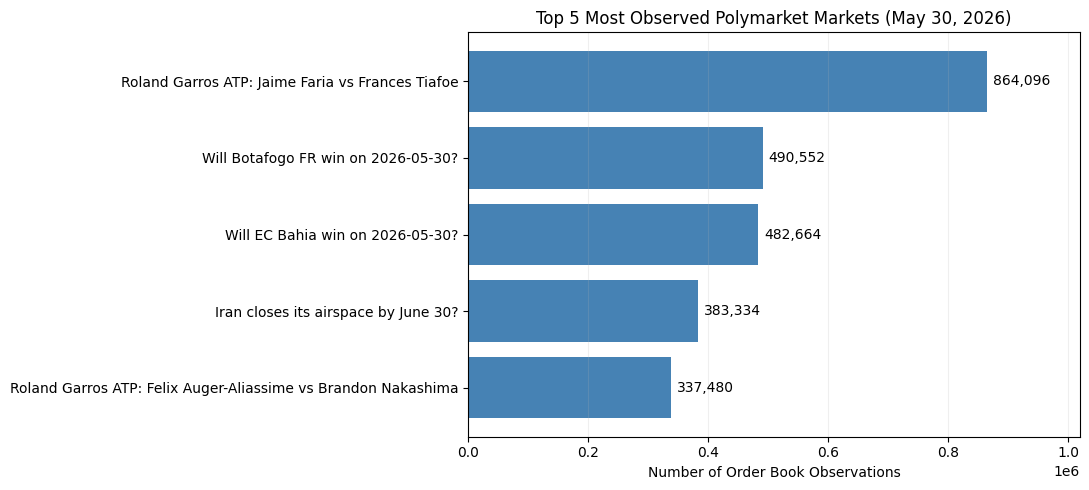

In [ ]:
# Visualize the five markets with the most hourly order book observations
import matplotlib.pyplot as plt

top5 = hourly_markets.nlargest(5, "observation_count").copy()
top5 = top5.sort_values("observation_count")

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    top5["title"],
    top5["observation_count"],
    color="steelblue"
)

for bar in bars:
    ax.text(
        bar.get_width() + 10000,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():,.0f}",
        va="center",
        fontsize=10
    )

ax.set_xlabel("Number of Order Book Observations")
ax.set_title("Top 5 Most Observed Polymarket Markets (May 30, 2026)")
ax.set_xlim(0, top5["observation_count"].max() * 1.18)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

All 1,813 markets represented in the one-hour Parquet dataset successfully match records in the Supabase market metadata table, producing a 100% match rate. This allows order book observation counts to be associated with market titles, event identifiers, cumulative trading volume, and recorded liquidity.

The most frequently observed market is the Roland Garros tennis match between Jaime Faria and Frances Tiafoe, with 864,096 observations during the hour. Other highly represented markets include Botafogo FR to win (490,552 observations), EC Bahia to win (482,664 observations), and Iran closing its airspace by June 30 (383,334 observations). Sports markets account for many of the highest observation counts, although geopolitical and political contracts are also represented.

A notable finding is that high hourly observation frequency does not necessarily correspond to high cumulative trading volume. For example, the Faria–Tiafoe tennis market records 864,096 observations but only approximately 40,949 in reported cumulative volume. In contrast, the China–Taiwan invasion contract records fewer observations (308,334) despite having approximately 31.27 million in cumulative volume. Several baseball markets also exhibit hundreds of thousands of observations despite relatively low reported cumulative trading volume.

These results demonstrate that order book observation counts and cumulative trading volume capture different dimensions of market activity. Observation frequency reflects how often records appear in the hourly dataset, whereas cumulative trading volume measures reported historical trading activity. Consequently, high observation counts should not be interpreted as evidence of high executed trading volume.

Markets with positive recorded volume: 1811
Spearman correlation: 0.003


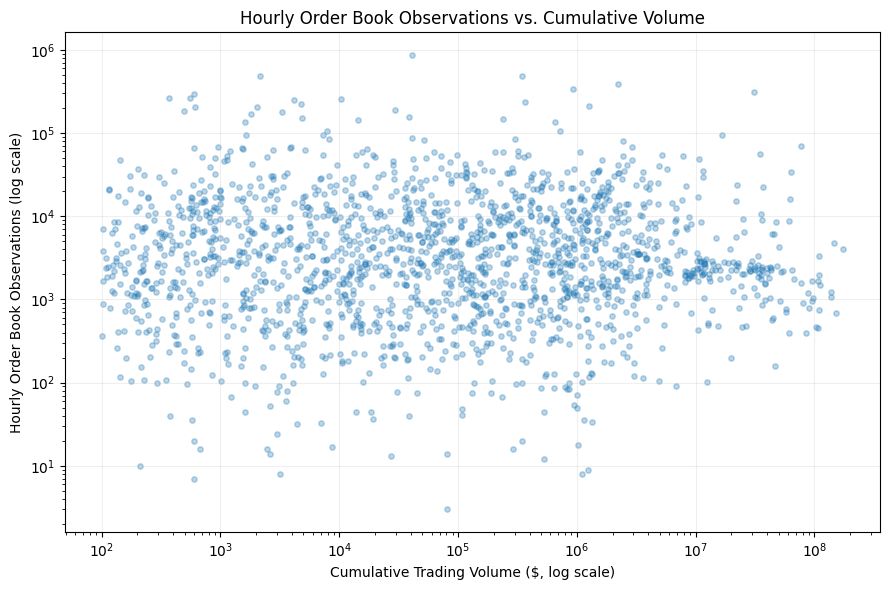

In [ ]:
# Compare hourly order book observation counts with cumulative market volume
import pandas as pd
import matplotlib.pyplot as plt

activity_volume = hourly_markets.copy()

activity_volume["volume_clob"] = pd.to_numeric(
    activity_volume["volume_clob"], errors="coerce"
)

activity_volume = activity_volume[
    (activity_volume["observation_count"] > 0) &
    (activity_volume["volume_clob"] > 0)
].copy()

rho = activity_volume["observation_count"].corr(
    activity_volume["volume_clob"],
    method="spearman"
)

print("Markets with positive recorded volume:", len(activity_volume))
print(f"Spearman correlation: {rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    activity_volume["volume_clob"],
    activity_volume["observation_count"],
    alpha=0.3,
    s=15
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Cumulative Trading Volume ($, log scale)")
ax.set_ylabel("Hourly Order Book Observations (log scale)")
ax.set_title("Hourly Order Book Observations vs. Cumulative Volume")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The scatterplot compares the number of order book observations recorded during the one-hour window with cumulative trading volume across Polymarket markets. Both axes use logarithmic scales to accommodate the substantial variation in market size and observation frequency. The visualization does not reveal a strong positive relationship between the two variables. Instead, markets with widely different cumulative trading volumes frequently exhibit similar hourly observation counts, with many markets recording approximately 1,000 to 20,000 observations regardless of their historical volume.

Considerable variation is also present among markets with comparable cumulative trading volume. For example, markets with approximately $100,000 in recorded volume range from fewer than 100 observations to tens of thousands of observations during the sampled hour. Additionally, some markets with cumulative volume exceeding $10 million have relatively modest hourly observation counts.

Overall, these findings suggest that cumulative trading volume alone does not adequately explain variation in hourly order book observation frequency. The two metrics represent different dimensions of market activity: cumulative volume reflects reported historical trading activity, whereas hourly observation counts describe the frequency of order book records within a specific observation window. However, differences in market type, market age, and data collection behavior may influence this relationship.

## Buy versus Sell

In [ ]:
# Compare BUY and SELL observation counts and displayed order sizes
side_summary = con.execute("""
    SELECT
        side,
        COUNT(*) AS observations,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS observation_pct,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size_count,
        ROUND(100.0 * COUNT(*) FILTER (WHERE size = 0) / COUNT(*), 2) AS zero_size_pct,
        ROUND(AVG(size), 2) AS mean_size,
        ROUND(MEDIAN(size), 2) AS median_size,
        ROUND(SUM(size), 2) AS total_observed_size
    FROM read_parquet('events.parquet')
    GROUP BY side
    ORDER BY side
""").df()

display(side_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,side,observations,observation_pct,zero_size_count,zero_size_pct,mean_size,median_size,total_observed_size
0,BUY,10495153,50.01,1792683,17.08,22863.29,300.0,2.399538e+11
1,SELL,10490488,49.99,1781303,16.98,22799.50,300.0,2.391779e+11


The one-hour Polymarket order book dataset contains 10,495,153 BUY observations (50.01%) and 10,490,488 SELL observations (49.99%), indicating an almost perfectly balanced distribution between the two sides. The difference of only 4,665 observations is negligible relative to the approximately 20.99 million total records. Zero-size observations are also similarly distributed, accounting for 17.08% of BUY records and 16.98% of SELL records.

Displayed order sizes exhibit substantial right-skewness on both sides. The mean BUY size is approximately 22,863.29, compared with 22,799.50 for SELL observations, while the median size is 300 for both. The large differences between the means and medians suggest that a relatively small number of very large displayed sizes have a substantial influence on the averages. Overall, BUY and SELL observations exhibit highly similar distributions in terms of frequency, typical size, and zero-size prevalence. However, these findings describe recorded order book observations rather than executed trading activity, and repeated observations may represent the same underlying liquidity.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

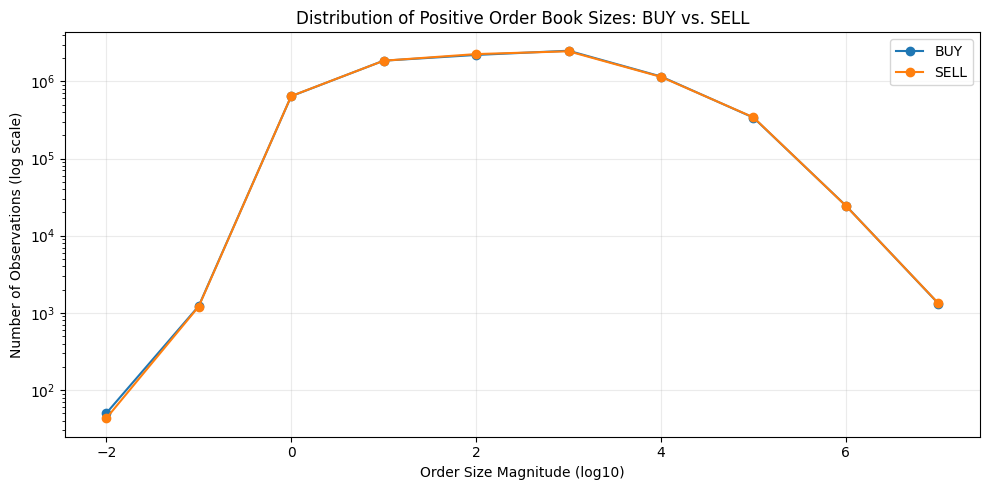

In [ ]:
# Compare distributions of positive displayed order sizes for BUY and SELL observations
import numpy as np
import matplotlib.pyplot as plt

size_distribution = con.execute("""
    SELECT
        side,
        FLOOR(LOG10(size)) AS log10_size,
        COUNT(*) AS observation_count
    FROM read_parquet('events.parquet')
    WHERE size > 0
    GROUP BY side, FLOOR(LOG10(size))
    ORDER BY side, log10_size
""").df()

fig, ax = plt.subplots(figsize=(10, 5))

for side in ["BUY", "SELL"]:
    subset = size_distribution[size_distribution["side"] == side]
    ax.plot(
        subset["log10_size"],
        subset["observation_count"],
        marker="o",
        label=side
    )

ax.set_yscale("log")
ax.set_xlabel("Order Size Magnitude (log10)")
ax.set_ylabel("Number of Observations (log scale)")
ax.set_title("Distribution of Positive Order Book Sizes: BUY vs. SELL")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count    1813.000000
mean       49.833001
std        10.773552
min         0.000000
25%        50.000000
50%        50.000000
75%        50.000000
max       100.000000
Name: buy_pct, dtype: float64


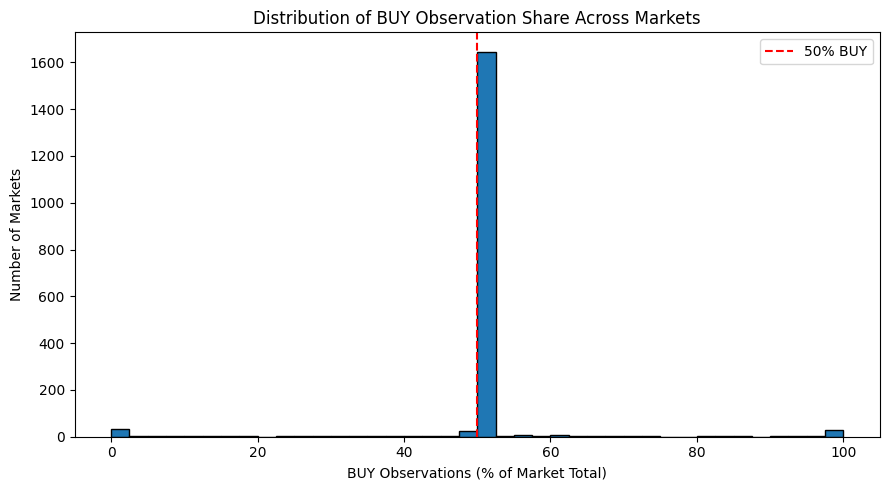

In [ ]:
# Measure BUY observation share within each market
market_side_balance = con.execute("""
    SELECT
        market,
        COUNT(*) AS total_observations,
        COUNT(*) FILTER (WHERE side = 'BUY') AS buy_observations,
        COUNT(*) FILTER (WHERE side = 'SELL') AS sell_observations,
        ROUND(
            100.0 * COUNT(*) FILTER (WHERE side = 'BUY') / COUNT(*),
            2
        ) AS buy_pct
    FROM read_parquet('events.parquet')
    WHERE side IN ('BUY', 'SELL')
    GROUP BY market
""").df()

print(market_side_balance["buy_pct"].describe())

plt.figure(figsize=(9, 5))
plt.hist(market_side_balance["buy_pct"], bins=40, edgecolor="black")
plt.axvline(50, color="red", linestyle="--", label="50% BUY")
plt.xlabel("BUY Observations (% of Market Total)")
plt.ylabel("Number of Markets")
plt.title("Distribution of BUY Observation Share Across Markets")
plt.legend()
plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

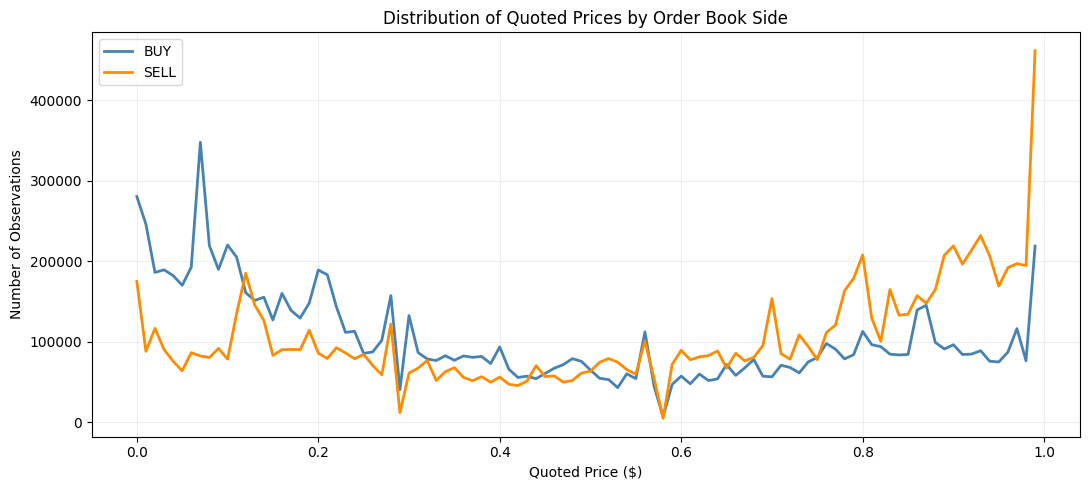

In [ ]:
# Examine the distribution of quoted prices by order book side
import pandas as pd
import matplotlib.pyplot as plt

price_distribution = con.execute("""
    SELECT
        side,
        FLOOR(price * 100) / 100 AS price_bin,
        COUNT(*) AS observation_count
    FROM read_parquet('events.parquet')
    WHERE price BETWEEN 0 AND 1
    GROUP BY side, price_bin
    ORDER BY side, price_bin
""").df()

fig, ax = plt.subplots(figsize=(11, 5))

for side, color in [("BUY", "steelblue"), ("SELL", "darkorange")]:
    subset = price_distribution[price_distribution["side"] == side]
    ax.plot(
        subset["price_bin"],
        subset["observation_count"],
        label=side,
        color=color,
        linewidth=2
    )

ax.set_xlabel("Quoted Price ($)")
ax.set_ylabel("Number of Observations")
ax.set_title("Distribution of Quoted Prices by Order Book Side")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

The distribution of quoted prices differs noticeably between BUY and SELL observations. BUY observations are more concentrated at lower price levels, particularly between $0.00 and $0.20, while SELL observations are more concentrated at higher prices, especially between $0.75 and $1.00.

Both sides have relatively similar observation frequencies across the middle of the price range. There are also noticeable spikes at specific price levels, suggesting that some quotes occur much more frequently than others.

This pattern is consistent with the structure of a limit order book, where buy orders generally quote lower prices than sell orders. However, these distributions aggregate observations across multiple markets, tokens, and timestamps, so they cannot be used to directly estimate bid-ask spreads or infer trading sentiment.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,side,observations,zero_size_count,mean_size,median_size,p90_size,p99_size,max_size
0,BUY,10495153,1792683,22863.29,300.0,22500.00,192585.68,33601887.56
1,SELL,10490488,1781303,22799.50,300.0,22132.25,195850.65,33601887.56


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

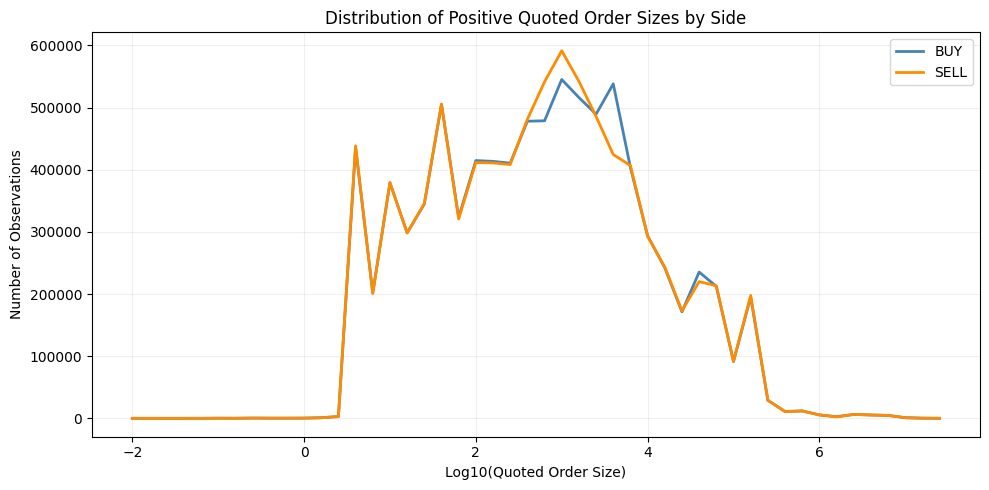

In [ ]:
# Summarize and compare positive quoted order sizes by BUY and SELL side
import numpy as np
import matplotlib.pyplot as plt

size_summary = con.execute("""
    SELECT
        side,
        COUNT(*) AS observations,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size_count,
        ROUND(AVG(size), 2) AS mean_size,
        ROUND(MEDIAN(size), 2) AS median_size,
        ROUND(QUANTILE_CONT(size, 0.90), 2) AS p90_size,
        ROUND(QUANTILE_CONT(size, 0.99), 2) AS p99_size,
        ROUND(MAX(size), 2) AS max_size
    FROM read_parquet('events.parquet')
    GROUP BY side
    ORDER BY side
""").df()

display(size_summary)

size_bins = con.execute("""
    SELECT
        side,
        FLOOR(LOG10(size) * 5) / 5 AS log_size_bin,
        COUNT(*) AS observation_count
    FROM read_parquet('events.parquet')
    WHERE size > 0
    GROUP BY side, log_size_bin
    ORDER BY side, log_size_bin
""").df()

fig, ax = plt.subplots(figsize=(10, 5))

for side, color in [("BUY", "steelblue"), ("SELL", "darkorange")]:
    subset = size_bins[size_bins["side"] == side]
    ax.plot(
        subset["log_size_bin"],
        subset["observation_count"],
        label=side,
        color=color,
        linewidth=2
    )

ax.set_xlabel("Log10(Quoted Order Size)")
ax.set_ylabel("Number of Observations")
ax.set_title("Distribution of Positive Quoted Order Sizes by Side")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

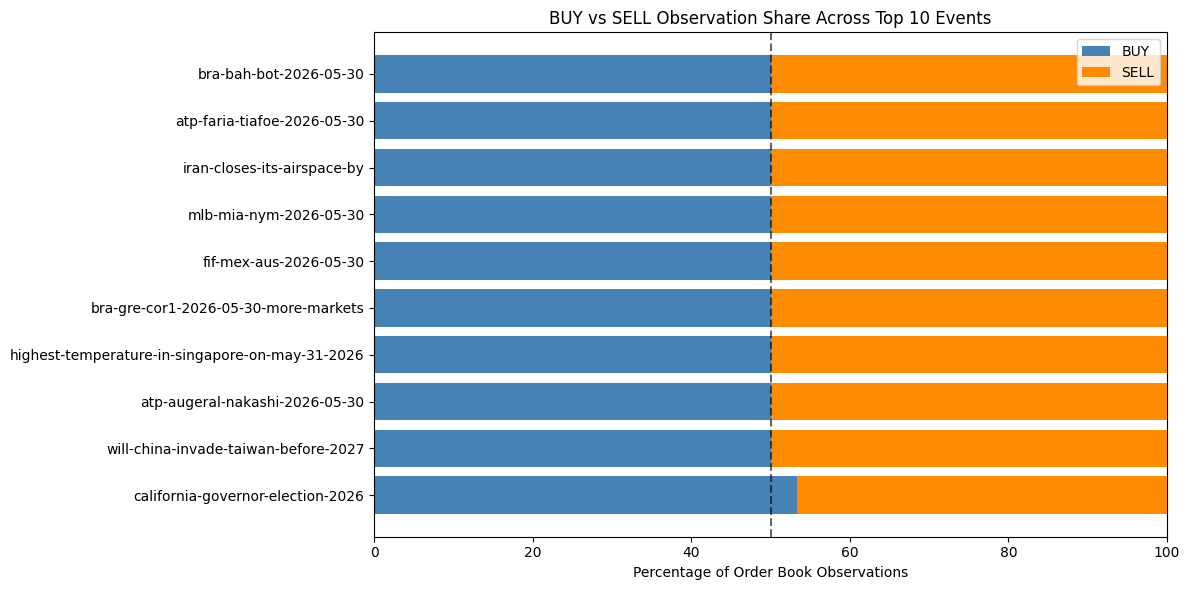

side,BUY,SELL,total,BUY_pct,SELL_pct
event_slug,,,,,
bra-bah-bot-2026-05-30,486608,486608,973216,50.00,50.00
atp-faria-tiafoe-2026-05-30,432614,432614,865228,50.00,50.00
iran-closes-its-airspace-by,301823,301823,603646,50.00,50.00
mlb-mia-nym-2026-05-30,249342,249342,498684,50.00,50.00
fif-mex-aus-2026-05-30,198442,198442,396884,50.00,50.00
bra-gre-cor1-2026-05-30-more-markets,189162,189163,378325,50.00,50.00
highest-temperature-in-singapore-on-may-31-2026,181916,181916,363832,50.00,50.00
atp-augeral-nakashi-2026-05-30,168740,168740,337480,50.00,50.00
will-china-invade-taiwan-before-2027,154167,154167,308334,50.00,50.00


In [ ]:
# Compare BUY and SELL observation shares across the 10 most observed events
import matplotlib.pyplot as plt
import numpy as np

event_side = con.execute("""
    SELECT
        market,
        side,
        COUNT(*) AS observations
    FROM read_parquet('events.parquet')
    WHERE side IN ('BUY', 'SELL')
    GROUP BY market, side
""").df()

event_side = event_side.merge(
    hourly_markets[["market", "event_slug"]].drop_duplicates(),
    on="market",
    how="left"
)

event_summary = (
    event_side.groupby(["event_slug", "side"])["observations"]
    .sum()
    .unstack(fill_value=0)
)

event_summary["total"] = event_summary["BUY"] + event_summary["SELL"]
event_summary = event_summary.nlargest(10, "total").copy()

event_summary["BUY_pct"] = 100 * event_summary["BUY"] / event_summary["total"]
event_summary["SELL_pct"] = 100 * event_summary["SELL"] / event_summary["total"]

event_summary = event_summary.sort_values("total")

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    event_summary.index,
    event_summary["BUY_pct"],
    label="BUY",
    color="steelblue"
)

ax.barh(
    event_summary.index,
    event_summary["SELL_pct"],
    left=event_summary["BUY_pct"],
    label="SELL",
    color="darkorange"
)

ax.axvline(50, color="black", linestyle="--", alpha=0.6)

ax.set_xlabel("Percentage of Order Book Observations")
ax.set_title("BUY vs SELL Observation Share Across Top 10 Events")
ax.set_xlim(0, 100)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

display(
    event_summary[
        ["BUY", "SELL", "total", "BUY_pct", "SELL_pct"]
    ].sort_values("total", ascending=False).round(2)
)

In [ ]:
# Compare median positive BUY and SELL quoted sizes across the top 10 events
top_events = event_summary.index.tolist()

event_sizes = con.execute("""
    SELECT
        market,
        side,
        MEDIAN(size) AS median_size
    FROM read_parquet('events.parquet')
    WHERE size > 0
      AND side IN ('BUY', 'SELL')
    GROUP BY market, side
""").df()

event_sizes = event_sizes.merge(
    hourly_markets[["market", "event_slug"]].drop_duplicates(),
    on="market",
    how="left"
)

# Use event-level medians directly from underlying observations,
# rather than averaging market-level medians
event_size_summary = con.execute("""
    SELECT market, side, size
    FROM read_parquet('events.parquet')
    WHERE size > 0
      AND side IN ('BUY', 'SELL')
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Identifying what one row means

In [ ]:
# Inspect the earliest raw order book records for the most observed market
top_market = hourly_markets.nlargest(
    1, "observation_count"
)["market"].iloc[0]

raw_sample = con.execute("""
    SELECT
        ts_ms,
        TO_TIMESTAMP(ts_ms / 1000.0) AS timestamp_utc,
        asset_id,
        side,
        price,
        size
    FROM read_parquet('events.parquet')
    WHERE market = ?
    ORDER BY ts_ms, asset_id, side, price
    LIMIT 50
""", [top_market]).df()

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)

display(raw_sample)

print("Unique timestamps:", raw_sample["ts_ms"].nunique())
print("Unique asset IDs:", raw_sample["asset_id"].nunique())
print("BUY rows:", (raw_sample["side"] == "BUY").sum())
print("SELL rows:", (raw_sample["side"] == "SELL").sum())

,ts_ms,timestamp_utc,asset_id,side,price,size
0,1780174800005,2026-05-30 21:00:00.005000+00:00,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.98,94908.92
1,1780174800005,2026-05-30 21:00:00.005000+00:00,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.98,94908.92
2,1780174800005,2026-05-30 21:00:00.005000+00:00,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.02,94908.92
3,1780174800005,2026-05-30 21:00:00.005000+00:00,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.02,94908.92
4,1780174800013,2026-05-30 21:00:00.013000+00:00,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.90,77327.38
5,1780174800013,2026-05-30 21:00:00.013000+00:00,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.10,77327.38
6,1780174800014,2026-05-30 21:00:00.014000+00:00,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.90,77327.38
7,1780174800014,2026-05-30 21:00:00.014000+00:00,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.10,77327.38
8,1780174800023,2026-05-30 21:00:00.023000+00:00,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.88,75.58
9,1780174800023,2026-05-30 21:00:00.023000+00:00,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.12,75.58


Unique timestamps: 17
Unique asset IDs: 2
BUY rows: 25
SELL rows: 25


In [ ]:
# Test complementary BUY/SELL pairing in the most observed market
pairing_check = con.execute("""
    WITH records AS (
        SELECT
            ts_ms,
            asset_id,
            side,
            ROUND(price, 6) AS price,
            ROUND(size, 6) AS size,
            COUNT(*) AS n
        FROM read_parquet('events.parquet')
        WHERE market = ?
        GROUP BY 1, 2, 3, 4, 5
    ),
    paired AS (
        SELECT
            a.side,
            a.n,
            b.n AS matching_count
        FROM records a
        LEFT JOIN records b
          ON a.ts_ms = b.ts_ms
         AND a.asset_id <> b.asset_id
         AND a.side <> b.side
         AND a.price = ROUND(1 - b.price, 6)
         AND a.size = b.size
    )
    SELECT
        side,
        SUM(n) AS total_rows,
        SUM(
            CASE WHEN matching_count IS NOT NULL
                 THEN LEAST(n, matching_count)
                 ELSE 0 END
        ) AS matched_rows,
        ROUND(
            100.0 * SUM(
                CASE WHEN matching_count IS NOT NULL
                     THEN LEAST(n, matching_count)
                     ELSE 0 END
            ) / SUM(n), 2
        ) AS matched_pct
    FROM paired
    GROUP BY side
    ORDER BY side
""", [top_market]).df()

display(pairing_check)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,side,total_rows,matched_rows,matched_pct
0,BUY,432048.0,432048.0,100.0
1,SELL,432048.0,432048.0,100.0


 record-level matching analysis was conducted on the Faria–Tiafoe market to investigate the near-perfect symmetry between BUY and SELL observations.

All 432,048 BUY records and 432,048 SELL records (100%) had corresponding records on the opposite outcome token with the same timestamp, identical quoted size, opposite side, and complementary prices summing to $1.

This provides strong evidence that the dataset contains mechanically mirrored representations of order book information for complementary binary outcomes.

As a result, aggregate BUY/SELL observation counts and quoted size distributions should not be interpreted as independent measures of buying and selling pressure. Such comparisons may primarily reflect the dataset's representation rather than meaningful market behavior.

The analysis does not yet establish whether rows represent full order book snapshots, incremental updates, or another form of recorded quote information.

In [ ]:
# Examine how many order book levels appear at each timestamp for one token
token_id = con.execute("""
    SELECT asset_id
    FROM read_parquet('events.parquet')
    WHERE market = ?
    LIMIT 1
""", [top_market]).fetchone()[0]

timestamp_structure = con.execute("""
    SELECT
        ts_ms,
        COUNT(*) AS rows_at_timestamp,
        COUNT(DISTINCT price) AS distinct_prices,
        COUNT(DISTINCT side) AS sides_present,
        MIN(price) AS min_price,
        MAX(price) AS max_price
    FROM read_parquet('events.parquet')
    WHERE market = ?
      AND asset_id = ?
    GROUP BY ts_ms
    ORDER BY ts_ms
    LIMIT 30
""", [top_market, token_id]).df()

display(timestamp_structure)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ts_ms,rows_at_timestamp,distinct_prices,sides_present,min_price,max_price
0,1780174800005,2,1,1,0.02,0.02
1,1780174800013,1,1,1,0.10,0.10
2,1780174800014,1,1,1,0.10,0.10
3,1780174800023,1,1,1,0.12,0.12
4,1780174800024,1,1,1,0.12,0.12
5,1780174800032,2,2,1,0.01,0.25
6,1780174800034,2,2,1,0.01,0.25
7,1780174800058,2,1,1,0.90,0.90
8,1780174800061,1,1,1,0.10,0.10
9,1780174800062,1,1,1,0.10,0.10


In [ ]:
# Examine whether zero-size records follow positive-size records at the same price level
zero_updates = con.execute("""
    WITH ordered AS (
        SELECT
            ts_ms,
            asset_id,
            side,
            price,
            size,
            LAG(size) OVER (
                PARTITION BY asset_id, side, price
                ORDER BY ts_ms
            ) AS previous_size
        FROM read_parquet('events.parquet')
        WHERE market = ?
    )
    SELECT
        ts_ms,
        asset_id,
        side,
        price,
        previous_size,
        size
    FROM ordered
    WHERE size = 0
      AND previous_size > 0
    ORDER BY ts_ms
    LIMIT 20
""", [top_market]).df()

display(zero_updates)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ts_ms,asset_id,side,price,previous_size,size
0,1780174800596,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.88,75.58,0.0
1,1780174800596,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.12,75.58,0.0
2,1780174801218,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.09,1000.00,0.0
3,1780174801218,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.91,1000.00,0.0
4,1780174801223,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.09,1000.00,0.0
5,1780174801223,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.91,1000.00,0.0
6,1780174807417,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.90,500.00,0.0
7,1780174807417,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.10,500.00,0.0
8,1780174807447,25124605170827842013178162303440485666749895976585223679436333610158344218617,BUY,0.91,185.00,0.0
9,1780174807447,103669054720080883576235095021266533295838946330146285348135941374042607523837,SELL,0.09,185.00,0.0


Inspection of the raw Parquet records suggests that the dataset contains incremental price-level observations rather than complete order book snapshots. Most timestamps contain only one or a few price levels, and approximately 17% of all observations have zero recorded size.

For the Faria–Tiafoe market, several price levels previously observed with positive quoted sizes subsequently appear with zero size. These changes frequently occur simultaneously across complementary outcome tokens, with opposite BUY/SELL sides and prices summing to $1.

This behavior is consistent with an order book update process in which a zero-size record indicates the removal or clearing of liquidity at a particular price level.

However, the precise semantics of the feed have not been independently verified. Repeated records and the absence of explicit event types mean that zero-size observations should not automatically be interpreted as cancellations or executed trades.

# Reconstruct one market

In [ ]:
# Check duplicate and conflicting updates for the selected outcome token
update_quality = con.execute("""
    WITH grouped AS (
        SELECT
            ts_ms,
            side,
            price,
            COUNT(*) AS row_count,
            COUNT(DISTINCT size) AS distinct_sizes
        FROM read_parquet('events.parquet')
        WHERE market = ?
          AND asset_id = ?
        GROUP BY ts_ms, side, price
    )
    SELECT
        SUM(row_count) AS total_rows,
        COUNT(*) AS unique_timestamp_side_price,
        SUM(row_count - 1) AS repeated_rows,
        COUNT(*) FILTER (
            WHERE distinct_sizes > 1
        ) AS conflicting_groups,
        MAX(distinct_sizes) AS max_distinct_sizes
    FROM grouped
""", [top_market, token_id]).df()

display(update_quality)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,unique_timestamp_side_price,repeated_rows,conflicting_groups,max_distinct_sizes
0,432048.0,349795,82253.0,13333,12


In [ ]:
conflicting_examples = con.execute("""
    WITH conflicts AS (
        SELECT ts_ms, side, price
        FROM read_parquet('events.parquet')
        WHERE market = ?
          AND asset_id = ?
        GROUP BY ts_ms, side, price
        HAVING COUNT(DISTINCT size) > 1
        ORDER BY ts_ms
        LIMIT 5
    )
    SELECT
        e.ts_ms,
        e.side,
        e.price,
        e.size
    FROM read_parquet('events.parquet') e
    JOIN conflicts c
      ON e.ts_ms = c.ts_ms
     AND e.side = c.side
     AND e.price = c.price
    WHERE e.market = ?
      AND e.asset_id = ?
    ORDER BY e.ts_ms, e.side, e.price, e.size
""", [top_market, token_id, top_market, token_id]).df()

display(conflicting_examples)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ts_ms,side,price,size
0,1780174800178,BUY,0.88,12254.99
1,1780174800178,BUY,0.88,12275.99
2,1780174800178,SELL,0.95,16050.40
3,1780174800178,SELL,0.95,16093.40
4,1780174800178,SELL,0.96,10351.58
5,1780174800178,SELL,0.96,10394.58
6,1780174800384,BUY,0.91,4768.40
7,1780174800384,BUY,0.91,4951.40
8,1780174800397,BUY,0.91,4318.40
9,1780174800397,BUY,0.91,4368.40


In [ ]:
conflicting_examples = con.execute("""
    WITH conflicts AS (
        SELECT ts_ms, side, price
        FROM read_parquet('events.parquet')
        WHERE market = ?
          AND asset_id = ?
        GROUP BY ts_ms, side, price
        HAVING COUNT(DISTINCT size) > 1
        ORDER BY ts_ms
        LIMIT 5
    )
    SELECT
        e.ts_ms,
        e.side,
        e.price,
        e.size
    FROM read_parquet('events.parquet') e
    JOIN conflicts c
      ON e.ts_ms = c.ts_ms
     AND e.side = c.side
     AND e.price = c.price
    WHERE e.market = ?
      AND e.asset_id = ?
    ORDER BY e.ts_ms, e.side, e.price, e.size
""", [top_market, token_id, top_market, token_id]).df()

display(conflicting_examples)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ts_ms,side,price,size
0,1780174800178,BUY,0.88,12254.99
1,1780174800178,BUY,0.88,12275.99
2,1780174800178,SELL,0.95,16050.40
3,1780174800178,SELL,0.95,16093.40
4,1780174800178,SELL,0.96,10351.58
5,1780174800178,SELL,0.96,10394.58
6,1780174800384,BUY,0.91,4768.40
7,1780174800384,BUY,0.91,4951.40
8,1780174800397,BUY,0.91,4318.40
9,1780174800397,BUY,0.91,4368.40


In [ ]:
row_order_check = con.execute("""
    SELECT
        file_row_number,
        ts_ms,
        side,
        price,
        size
    FROM read_parquet(
        'events.parquet',
        file_row_number = true
    )
    WHERE market = ?
      AND asset_id = ?
      AND ts_ms IN (
          1780174800178,
          1780174800384,
          1780174800397
      )
    ORDER BY file_row_number
""", [top_market, token_id]).df()

display(row_order_check)

,file_row_number,ts_ms,side,price,size
0,1507,1780174800178,SELL,0.95,16093.40
1,1508,1780174800178,BUY,0.88,12275.99
2,1510,1780174800178,BUY,0.88,12254.99
3,1512,1780174800178,BUY,0.10,79227.38
4,1515,1780174800178,SELL,0.96,10351.58
5,1517,1780174800178,SELL,0.95,16050.40
6,1519,1780174800178,SELL,0.96,10394.58
7,2611,1780174800384,BUY,0.91,4951.40
8,2614,1780174800384,BUY,0.91,4768.40
9,2749,1780174800397,BUY,0.91,4951.40


In [ ]:
# Check whether physical Parquet row order follows timestamp order
ordering_check = con.execute("""
    WITH ordered AS (
        SELECT
            file_row_number,
            ts_ms,
            LAG(ts_ms) OVER (
                ORDER BY file_row_number
            ) AS previous_ts
        FROM read_parquet(
            'events.parquet',
            file_row_number = true
        )
    )
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE ts_ms < previous_ts
        ) AS backward_timestamps,
        COUNT(*) FILTER (
            WHERE ts_ms = previous_ts
        ) AS same_timestamp,
        COUNT(*) FILTER (
            WHERE ts_ms > previous_ts
        ) AS forward_timestamps
    FROM ordered
""").df()

display(ordering_check)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,backward_timestamps,same_timestamp,forward_timestamps
0,20985641,0,18281765,2703875


In [ ]:
# Load the first 30 updates in original file order
updates = con.execute("""
    SELECT
        file_row_number,
        ts_ms,
        side,
        price,
        size
    FROM read_parquet(
        'events.parquet',
        file_row_number = true
    )
    WHERE market = ?
      AND asset_id = ?
    ORDER BY file_row_number
    LIMIT 30
""", [top_market, token_id]).df()

# Maintain the observed price levels
book = {"BUY": {}, "SELL": {}}

history = []

for row in updates.itertuples(index=False):
    side = row.side
    price = row.price
    size = row.size

    if size == 0:
        book[side].pop(price, None)
    else:
        book[side][price] = size

    history.append({
        "file_row_number": row.file_row_number,
        "side": side,
        "price": price,
        "size": size,
        "known_buy_levels": len(book["BUY"]),
        "known_sell_levels": len(book["SELL"])
    })

import pandas as pd

display(pd.DataFrame(history))
print("Observed book after 30 updates:")
print(book)

,file_row_number,side,price,size,known_buy_levels,known_sell_levels
0,35,BUY,0.02,94908.92,1,0
1,41,BUY,0.02,94908.92,1,0
2,79,BUY,0.10,77327.38,2,0
3,81,BUY,0.10,77327.38,2,0
4,133,BUY,0.12,75.58,3,0
5,139,BUY,0.12,75.58,3,0
6,205,BUY,0.01,437501.28,4,0
7,209,BUY,0.25,900.68,5,0
8,212,BUY,0.01,437501.28,5,0
9,214,BUY,0.25,900.68,5,0


Observed book after 30 updates:
{'BUY': {0.02: 94908.92, 0.1: 79227.38, 0.12: 75.58, 0.01: 437501.28, 0.25: 900.68, 0.9: 14631.9, 0.84: 1432.0, 0.89: 11556.8, 0.09: 1500.0, 0.91: 1065.4, 0.88: 12254.99}, 'SELL': {0.95: 16093.4}}


In [ ]:
# Load all updates for one outcome token in file order
token_updates = con.execute("""
    SELECT
        file_row_number,
        ts_ms,
        side,
        price,
        size
    FROM read_parquet(
        'events.parquet',
        file_row_number = true
    )
    WHERE market = ?
      AND asset_id = ?
    ORDER BY file_row_number
""", [top_market, token_id]).df()

book = {"BUY": {}, "SELL": {}}
history = []

for i, row in enumerate(token_updates.itertuples(index=False)):
    if row.size == 0:
        book[row.side].pop(row.price, None)
    else:
        book[row.side][row.price] = row.size

    # Record diagnostics every 1,000 updates
    if (i + 1) % 1000 == 0:
        best_bid = max(book["BUY"], default=None)
        best_ask = min(book["SELL"], default=None)

        history.append({
            "updates_processed": i + 1,
            "timestamp": pd.to_datetime(row.ts_ms, unit="ms", utc=True),
            "buy_levels": len(book["BUY"]),
            "sell_levels": len(book["SELL"]),
            "observed_best_bid": best_bid,
            "observed_best_ask": best_ask,
            "observed_spread": (
                best_ask - best_bid
                if best_bid is not None and best_ask is not None
                else None
            )
        })

reconstruction_history = pd.DataFrame(history)

display(reconstruction_history.head(10))
display(reconstruction_history.tail(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,updates_processed,timestamp,buy_levels,sell_levels,observed_best_bid,observed_best_ask,observed_spread
0,1000,2026-05-30 21:00:07.998000+00:00,27,7,0.92,0.93,0.01
1,2000,2026-05-30 21:00:13.861000+00:00,28,7,0.92,0.93,0.01
2,3000,2026-05-30 21:00:20.294000+00:00,27,7,0.91,0.92,0.01
3,4000,2026-05-30 21:00:26.488000+00:00,28,8,0.91,0.92,0.01
4,5000,2026-05-30 21:00:31.535000+00:00,36,6,0.92,0.94,0.02
5,6000,2026-05-30 21:00:36.070000+00:00,36,6,0.93,0.94,0.01
6,7000,2026-05-30 21:00:39.428000+00:00,35,7,0.92,0.93,0.01
7,8000,2026-05-30 21:00:44.398000+00:00,36,7,0.92,0.93,0.01
8,9000,2026-05-30 21:00:48.553000+00:00,36,6,0.92,0.94,0.02
9,10000,2026-05-30 21:00:53.259000+00:00,35,6,0.92,0.94,0.02


,updates_processed,timestamp,buy_levels,sell_levels,observed_best_bid,observed_best_ask,observed_spread
422,423000,2026-05-30 21:58:15.875000+00:00,29,44,0.93,0.18,-0.75
423,424000,2026-05-30 21:58:24.012000+00:00,28,43,0.93,0.18,-0.75
424,425000,2026-05-30 21:58:29.070000+00:00,28,45,0.93,0.18,-0.75
425,426000,2026-05-30 21:58:41.362000+00:00,28,45,0.93,0.18,-0.75
426,427000,2026-05-30 21:58:49.922000+00:00,28,45,0.93,0.18,-0.75
427,428000,2026-05-30 21:59:06.294000+00:00,28,49,0.93,0.18,-0.75
428,429000,2026-05-30 21:59:21.933000+00:00,28,50,0.93,0.18,-0.75
429,430000,2026-05-30 21:59:33.722000+00:00,28,47,0.93,0.18,-0.75
430,431000,2026-05-30 21:59:46.241000+00:00,28,47,0.93,0.18,-0.75
431,432000,2026-05-30 21:59:59.564000+00:00,28,44,0.93,0.18,-0.75


In [ ]:
suspicious_level = con.execute("""
    SELECT
        file_row_number,
        ts_ms,
        TO_TIMESTAMP(ts_ms / 1000.0) AS timestamp_utc,
        side,
        price,
        size
    FROM read_parquet(
        'events.parquet',
        file_row_number = true
    )
    WHERE market = ?
      AND asset_id = ?
      AND side = 'SELL'
      AND ROUND(price, 6) = 0.18
    ORDER BY file_row_number
""", [top_market, token_id]).df()

print("Total observations:", len(suspicious_level))
print("Zero-size observations:",
      (suspicious_level["size"] == 0).sum())

print("\nFirst 15 observations:")
display(suspicious_level.head(15))

print("\nLast 15 observations:")
display(suspicious_level.tail(15))

Total observations: 12
Zero-size observations: 0

First 15 observations:


,file_row_number,ts_ms,timestamp_utc,side,price,size
0,19307251,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,210.00
1,19307254,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,390.00
2,19307255,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,210.00
3,19307258,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,390.00
4,19309002,1780178116409,2026-05-30 21:55:16.409000+00:00,SELL,0.18,395.00
5,19309020,1780178116411,2026-05-30 21:55:16.411000+00:00,SELL,0.18,395.00
6,19333197,1780178120075,2026-05-30 21:55:20.075000+00:00,SELL,0.18,339.44
7,19333241,1780178120080,2026-05-30 21:55:20.080000+00:00,SELL,0.18,339.44
8,19333649,1780178120124,2026-05-30 21:55:20.124000+00:00,SELL,0.18,129.44
9,19333652,1780178120124,2026-05-30 21:55:20.124000+00:00,SELL,0.18,5.00



Last 15 observations:


,file_row_number,ts_ms,timestamp_utc,side,price,size
0,19307251,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,210.00
1,19307254,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,390.00
2,19307255,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,210.00
3,19307258,1780178116154,2026-05-30 21:55:16.154000+00:00,SELL,0.18,390.00
4,19309002,1780178116409,2026-05-30 21:55:16.409000+00:00,SELL,0.18,395.00
5,19309020,1780178116411,2026-05-30 21:55:16.411000+00:00,SELL,0.18,395.00
6,19333197,1780178120075,2026-05-30 21:55:20.075000+00:00,SELL,0.18,339.44
7,19333241,1780178120080,2026-05-30 21:55:20.080000+00:00,SELL,0.18,339.44
8,19333649,1780178120124,2026-05-30 21:55:20.124000+00:00,SELL,0.18,129.44
9,19333652,1780178120124,2026-05-30 21:55:20.124000+00:00,SELL,0.18,5.00


To reconstruct the Faria–Tiafoe order book, we processed price-level observations chronologically, assuming that positive sizes represented updated liquidity and zero sizes indicated removal of a price level.

Initially, the reconstructed order book appeared reasonable, with a best bid of $0.92 and a best ask of $0.93.

However, toward the end of the hour, our algorithm reported a best bid of $0.93 and a best ask of $0.18, producing a negative spread of $0.75.

Tracing the $0.18 SELL level revealed that it appeared 12 times over approximately four seconds, with a final reported size of 5 shares. No subsequent zero-size update was recorded.

As a result, our reconstruction continued treating the $0.18 quote as active for approximately 4 minutes and 40 seconds.

This demonstrated a critical limitation: without independently verifying the event semantics and completeness of the feed, the last observed quantity at a price level cannot necessarily be treated as its current quantity.

The reconstruction failure does not prove that data is missing, but it shows why historical order book analysis requires careful validation.

In [ ]:
market_window = con.execute("""
    SELECT
        DATE_TRUNC(
            'second',
            TO_TIMESTAMP(ts_ms / 1000.0)
        ) AS second_utc,
        side,
        COUNT(*) AS updates,
        COUNT(DISTINCT price) AS distinct_prices,
        ROUND(MIN(price), 3) AS min_price,
        ROUND(MAX(price), 3) AS max_price,
        ROUND(AVG(price), 3) AS avg_price,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size_updates
    FROM read_parquet('events.parquet')
    WHERE market = ?
      AND asset_id = ?
      AND ts_ms BETWEEN 1780178115000 AND 1780178125000
    GROUP BY 1, 2
    ORDER BY 1, 2
""", [top_market, token_id]).df()

display(market_window)

,second_utc,side,updates,distinct_prices,min_price,max_price,avg_price,zero_size_updates
0,2026-05-30 21:55:15+00:00,BUY,16,4,0.13,0.18,0.157,0
1,2026-05-30 21:55:15+00:00,SELL,117,15,0.19,0.99,0.728,8
2,2026-05-30 21:55:16+00:00,BUY,22,7,0.06,0.18,0.151,4
3,2026-05-30 21:55:16+00:00,SELL,99,13,0.18,0.97,0.700,8
4,2026-05-30 21:55:17+00:00,BUY,6,2,0.14,0.15,0.147,0
5,2026-05-30 21:55:17+00:00,SELL,72,11,0.21,0.93,0.777,16
6,2026-05-30 21:55:18+00:00,BUY,12,4,0.08,0.17,0.140,0
7,2026-05-30 21:55:18+00:00,SELL,46,12,0.21,0.93,0.704,8
8,2026-05-30 21:55:19+00:00,BUY,6,3,0.01,0.17,0.107,0
9,2026-05-30 21:55:19+00:00,SELL,34,9,0.19,0.93,0.599,10


In [ ]:
# Trace the suspicious high BUY level
high_bid_history = con.execute("""
    SELECT
        file_row_number,
        TO_TIMESTAMP(ts_ms / 1000.0) AS timestamp_utc,
        side,
        price,
        size
    FROM read_parquet(
        'events.parquet',
        file_row_number = true
    )
    WHERE market = ?
      AND asset_id = ?
      AND side = 'BUY'
      AND ROUND(price, 6) = 0.93
    ORDER BY file_row_number
""", [top_market, token_id]).df()

print("Total observations:", len(high_bid_history))
print("Zero-size observations:",
      (high_bid_history["size"] == 0).sum())

print("\nFirst observations:")
display(high_bid_history.head(10))

print("\nLast observations:")
display(high_bid_history.tail(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total observations: 322
Zero-size observations: 14

First observations:


,file_row_number,timestamp_utc,side,price,size
0,171389,2026-05-30 21:00:29.103000+00:00,BUY,0.93,5.00
1,171423,2026-05-30 21:00:29.103000+00:00,BUY,0.93,5.00
2,173562,2026-05-30 21:00:29.406000+00:00,BUY,0.93,10.00
3,173564,2026-05-30 21:00:29.407000+00:00,BUY,0.93,10.00
4,175480,2026-05-30 21:00:29.716000+00:00,BUY,0.93,22.00
5,175502,2026-05-30 21:00:29.718000+00:00,BUY,0.93,22.00
6,178200,2026-05-30 21:00:30.097000+00:00,BUY,0.93,4.85
7,178203,2026-05-30 21:00:30.097000+00:00,BUY,0.93,4.85
8,178288,2026-05-30 21:00:30.105000+00:00,BUY,0.93,4.85
9,178291,2026-05-30 21:00:30.105000+00:00,BUY,0.93,4.85



Last observations:


,file_row_number,timestamp_utc,side,price,size
312,772744,2026-05-30 21:02:15.309000+00:00,BUY,0.93,5.0
313,772768,2026-05-30 21:02:15.312000+00:00,BUY,0.93,5.0
314,775952,2026-05-30 21:02:15.941000+00:00,BUY,0.93,10.0
315,775954,2026-05-30 21:02:15.941000+00:00,BUY,0.93,10.0
316,777291,2026-05-30 21:02:16.197000+00:00,BUY,0.93,5.0
317,777301,2026-05-30 21:02:16.198000+00:00,BUY,0.93,5.0
318,777669,2026-05-30 21:02:16.266000+00:00,BUY,0.93,10.0
319,777675,2026-05-30 21:02:16.267000+00:00,BUY,0.93,10.0
320,785199,2026-05-30 21:02:17.563000+00:00,BUY,0.93,5.0
321,785273,2026-05-30 21:02:17.582000+00:00,BUY,0.93,5.0


In [ ]:
# Inspect the remaining BUY levels in our reconstructed book

remaining_bids = []

for price, size in sorted(
    book["BUY"].items(),
    reverse=True
)[:15]:

    matching = token_updates[
        (token_updates["side"] == "BUY") &
        (token_updates["price"].round(6) == round(price, 6))
    ]

    last = matching.iloc[-1]

    remaining_bids.append({
        "price": price,
        "reconstructed_size": size,
        "last_observed_utc": pd.to_datetime(
            last["ts_ms"], unit="ms", utc=True
        ),
        "last_observed_size": last["size"]
    })

display(pd.DataFrame(remaining_bids))

,price,reconstructed_size,last_observed_utc,last_observed_size
0,0.93,5.00,2026-05-30 21:02:17.582000+00:00,5.00
1,0.77,122.00,2026-05-30 21:18:22.755000+00:00,122.00
2,0.61,409.36,2026-05-30 21:29:38.081000+00:00,409.36
3,0.57,25.00,2026-05-30 21:31:01.732000+00:00,25.00
4,0.31,159.15,2026-05-30 21:46:15.077000+00:00,159.15
5,0.28,53.00,2026-05-30 21:57:33.168000+00:00,53.00
6,0.25,81.41,2026-05-30 21:58:25.592000+00:00,81.41
7,0.24,4849.32,2026-05-30 21:59:59.646000+00:00,4849.32
8,0.23,18824.32,2026-05-30 21:59:52.396000+00:00,18824.32
9,0.22,3555.04,2026-05-30 21:59:58.271000+00:00,3555.04


The reconstructed order book retains several high BUY price levels that were last observed much earlier in the hour. For example, the 0.93 bid was last updated at 21:02, while more recent bids near 0.24 were observed at 21:59. This suggests that older price levels may be incorrectly treated as active, producing an unrealistic negative bid-ask spread. The results highlight the difficulty of reconstructing an accurate order book without verifying that all updates and removals are captured.

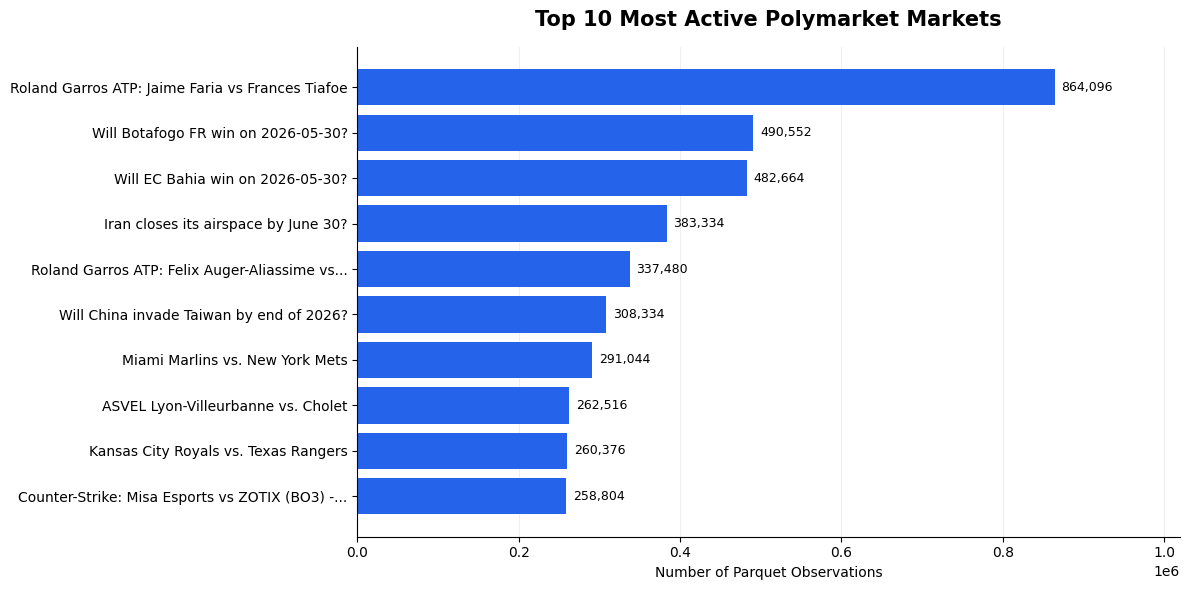

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import textwrap

top10 = (
    hourly_markets
    .sort_values("observation_count", ascending=False)
    .head(10)
    .copy()
)

top10["short_title"] = top10["title"].apply(
    lambda x: textwrap.shorten(str(x), width=48, placeholder="...")
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top10["short_title"][::-1],
    top10["observation_count"][::-1],
    color="#2563EB"
)

ax.bar_label(
    bars,
    labels=[
        f"{v:,.0f}"
        for v in top10["observation_count"][::-1]
    ],
    padding=5,
    fontsize=9
)

ax.set_title(
    "Top 10 Most Active Polymarket Markets",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Parquet Observations")
ax.set_ylabel("")
ax.set_xlim(0, top10["observation_count"].max() * 1.18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "01_top_10_markets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

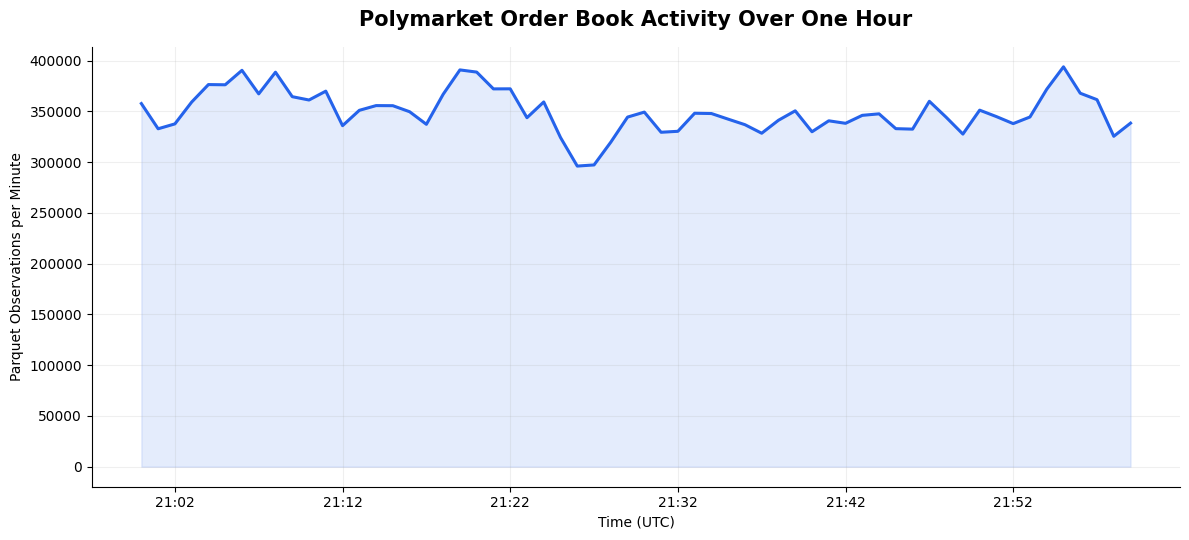

Average observations per minute: 349,761
Peak observations per minute: 393,899
Average active markets per minute: 1,480


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Count observations per minute across all markets
minute_activity = con.execute("""
    SELECT
        DATE_TRUNC(
            'minute',
            TO_TIMESTAMP(ts_ms / 1000.0)
        ) AS minute_utc,
        COUNT(*) AS observations,
        COUNT(DISTINCT market) AS active_markets
    FROM read_parquet('events.parquet')
    GROUP BY 1
    ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    minute_activity["minute_utc"],
    minute_activity["observations"],
    color="#2563EB",
    linewidth=2.2
)

ax.fill_between(
    minute_activity["minute_utc"],
    minute_activity["observations"],
    alpha=0.12,
    color="#2563EB"
)

ax.set_title(
    "Polymarket Order Book Activity Over One Hour",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Parquet Observations per Minute")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=mdates.UTC))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=10, tz=mdates.UTC))

ax.grid(alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "02_market_activity_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average observations per minute:",
      f"{minute_activity['observations'].mean():,.0f}")

print("Peak observations per minute:",
      f"{minute_activity['observations'].max():,.0f}")

print("Average active markets per minute:",
      f"{minute_activity['active_markets'].mean():,.0f}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

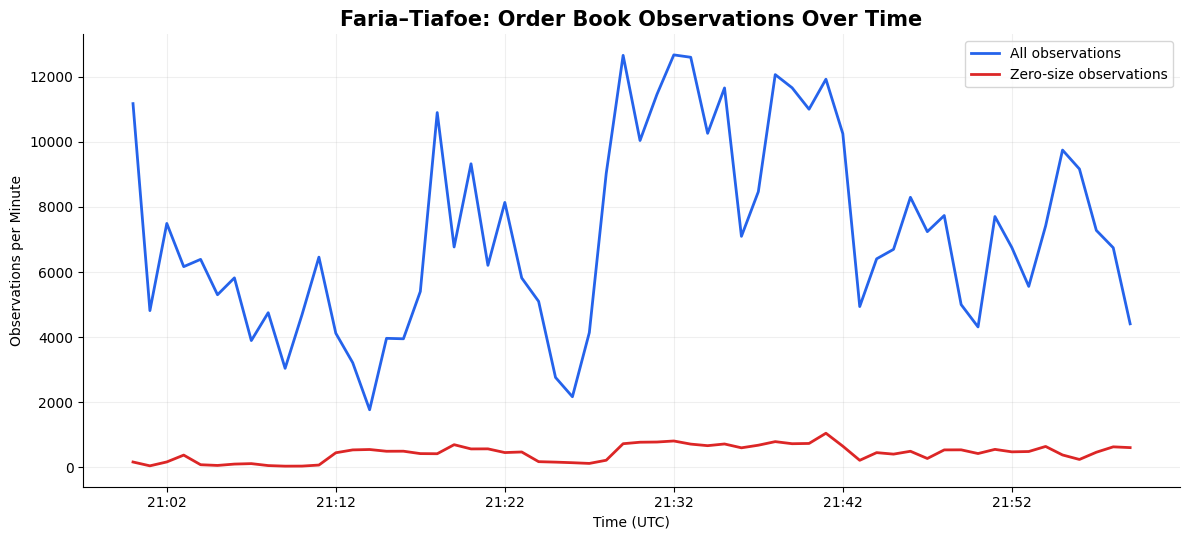

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

faria_activity = con.execute("""
    SELECT
        DATE_TRUNC(
            'minute',
            TO_TIMESTAMP(ts_ms / 1000.0)
        ) AS minute_utc,
        COUNT(*) AS observations,
        COUNT(*) FILTER (WHERE size = 0) AS zero_size_observations
    FROM read_parquet('events.parquet')
    WHERE market = ?
      AND asset_id = ?
    GROUP BY 1
    ORDER BY 1
""", [top_market, token_id]).df()

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    faria_activity["minute_utc"],
    faria_activity["observations"],
    linewidth=2,
    color="#2563EB",
    label="All observations"
)

ax.plot(
    faria_activity["minute_utc"],
    faria_activity["zero_size_observations"],
    linewidth=2,
    color="#DC2626",
    label="Zero-size observations"
)

ax.set_title(
    "Faria–Tiafoe: Order Book Observations Over Time",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Observations per Minute")

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)

ax.xaxis.set_major_locator(
    mdates.MinuteLocator(interval=10, tz=mdates.UTC)
)

ax.legend()
ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "03_faria_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_1994/3217852311.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), 12000), random_state=42))


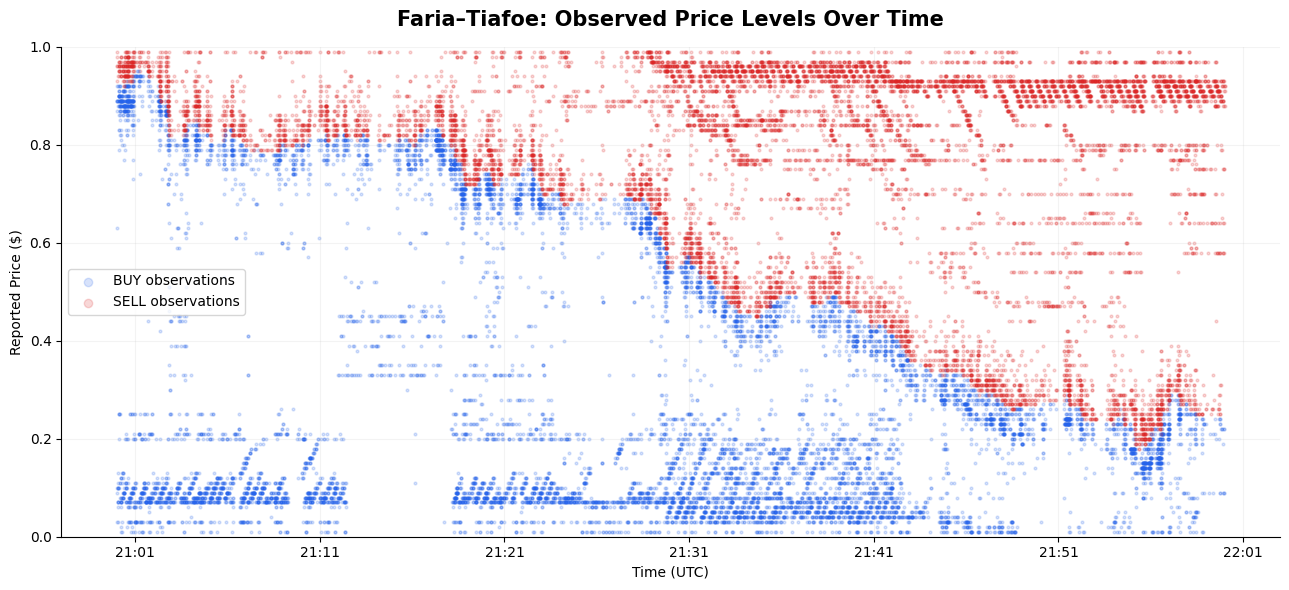

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Use the single-token observations already loaded
price_data = token_updates[token_updates["size"] > 0].copy()

price_data["timestamp"] = pd.to_datetime(
    price_data["ts_ms"], unit="ms", utc=True
)

# Sample points for readability, keeping both sides represented
sampled = (
    price_data.groupby("side", group_keys=False)
    .apply(lambda x: x.sample(min(len(x), 12000), random_state=42))
)

fig, ax = plt.subplots(figsize=(13, 6))

for side, color in [("BUY", "#2563EB"), ("SELL", "#DC2626")]:
    subset = sampled[sampled["side"] == side]

    ax.scatter(
        subset["timestamp"],
        subset["price"],
        s=4,
        alpha=0.18,
        color=color,
        label=f"{side} observations"
    )

ax.set_title(
    "Faria–Tiafoe: Observed Price Levels Over Time",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Reported Price ($)")
ax.set_ylim(0, 1)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)

ax.xaxis.set_major_locator(
    mdates.MinuteLocator(interval=10, tz=mdates.UTC)
)

ax.legend(markerscale=3)
ax.grid(alpha=0.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "04_faria_price_evolution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Observed BUY and SELL price levels exhibit a substantial downward shift throughout the hour, with a particularly noticeable decline around 21:30 UTC. This suggests a significant repricing of the selected outcome token during the tennis match. However, our reconstruction continued retaining higher BUY levels from earlier in the hour, contributing to an unrealistic negative bid-ask spread. The visualization highlights why historical price observations cannot automatically be treated as simultaneously active quotes.

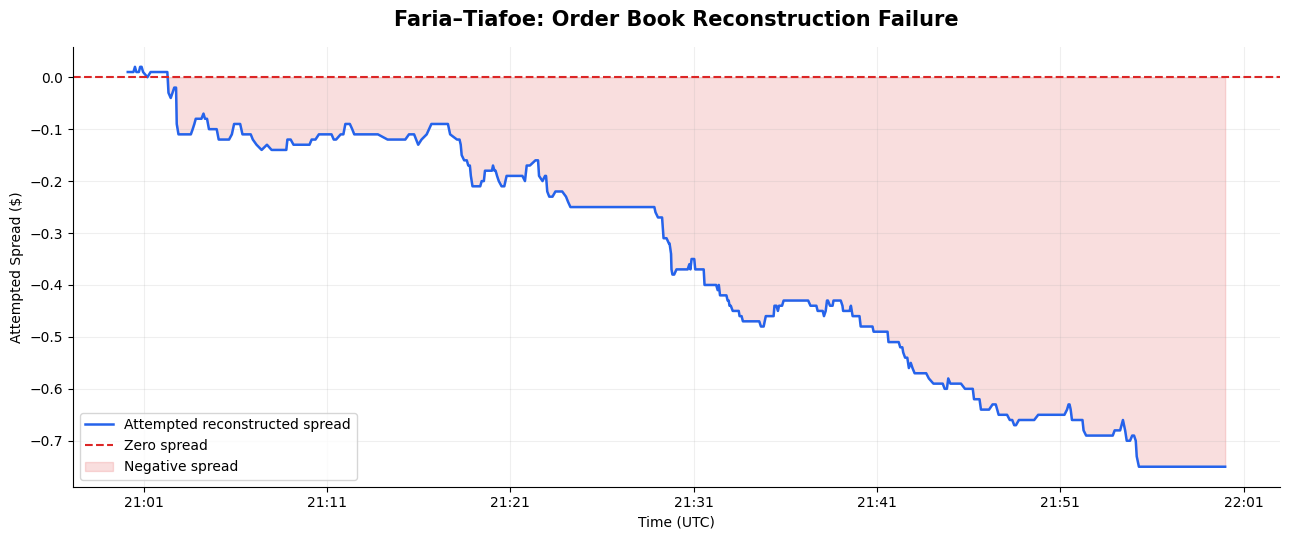

First negative spread: 2026-05-30 21:02:21.220000+00:00
Percentage of checkpoints with negative spreads: 96.1%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

spread_data = reconstruction_history.dropna(
    subset=["observed_spread"]
).copy()

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(
    spread_data["timestamp"],
    spread_data["observed_spread"],
    color="#2563EB",
    linewidth=1.8,
    label="Attempted reconstructed spread"
)

ax.axhline(
    y=0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="Zero spread"
)

ax.fill_between(
    spread_data["timestamp"],
    spread_data["observed_spread"],
    0,
    where=spread_data["observed_spread"] < 0,
    color="#DC2626",
    alpha=0.15,
    label="Negative spread"
)

ax.set_title(
    "Faria–Tiafoe: Order Book Reconstruction Failure",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Attempted Spread ($)")

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)

ax.xaxis.set_major_locator(
    mdates.MinuteLocator(interval=10, tz=mdates.UTC)
)

ax.grid(alpha=0.2)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "05_reconstruction_failure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "First negative spread:",
    spread_data.loc[
        spread_data["observed_spread"] < 0,
        "timestamp"
    ].min()
)

print(
    "Percentage of checkpoints with negative spreads:",
    f"{100 * (spread_data['observed_spread'] < 0).mean():.1f}%"
)

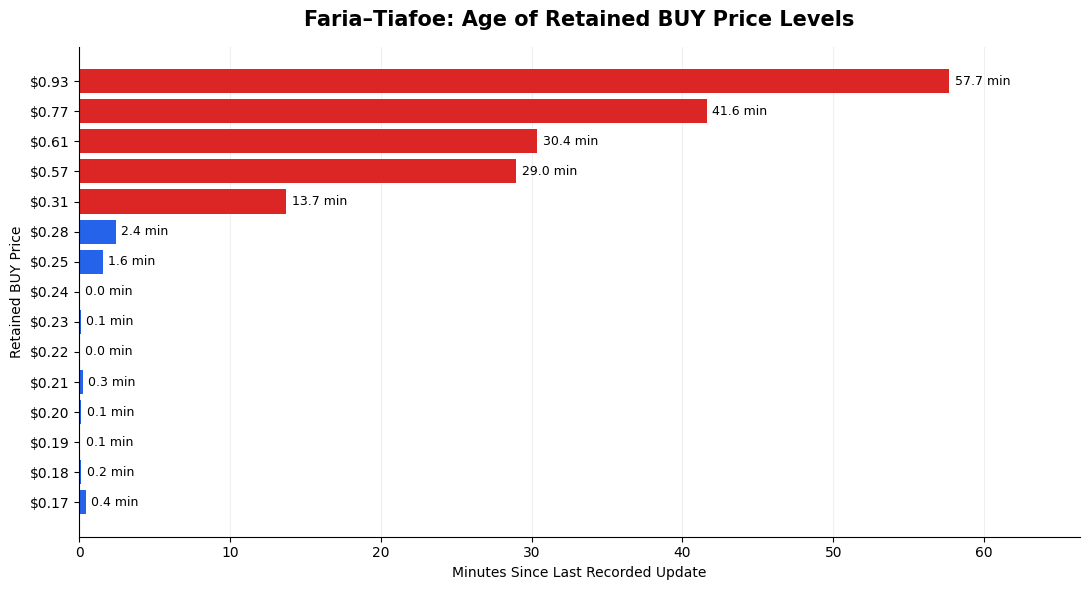

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the final reconstructed BUY book
remaining_bids = []

end_time = pd.to_datetime(
    token_updates["ts_ms"].max(),
    unit="ms",
    utc=True
)

# Find the last observation for each BUY price
buy_updates = token_updates[
    token_updates["side"] == "BUY"
].copy()

last_buy_updates = (
    buy_updates
    .sort_values("file_row_number")
    .groupby("price")
    .tail(1)
    .set_index("price")
)

for price, size in book["BUY"].items():

    if price not in last_buy_updates.index:
        continue

    last = last_buy_updates.loc[price]

    last_time = pd.to_datetime(
        last["ts_ms"],
        unit="ms",
        utc=True
    )

    age_minutes = (
        end_time - last_time
    ).total_seconds() / 60

    remaining_bids.append({
        "price": price,
        "size": size,
        "age_minutes": age_minutes
    })

bid_age = pd.DataFrame(remaining_bids)

# Focus on the 15 highest retained BUY prices
bid_age = (
    bid_age
    .sort_values("price", ascending=False)
    .head(15)
    .sort_values("price")
)

fig, ax = plt.subplots(figsize=(11, 6))

colors = [
    "#DC2626" if age > 10 else "#2563EB"
    for age in bid_age["age_minutes"]
]

bars = ax.barh(
    bid_age["price"].map(lambda p: f"${p:.2f}"),
    bid_age["age_minutes"],
    color=colors
)

ax.bar_label(
    bars,
    fmt="%.1f min",
    padding=4,
    fontsize=9
)

ax.set_title(
    "Faria–Tiafoe: Age of Retained BUY Price Levels",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Minutes Since Last Recorded Update")
ax.set_ylabel("Retained BUY Price")

ax.set_xlim(
    0,
    max(bid_age["age_minutes"]) * 1.15
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "06_retained_bid_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Processed observations: 432,048
Expiration threshold: 5 minutes
Price-level expirations: 60
Valid spread samples: 433
Negative spread percentage: 50.81%
Final reconstructed spread: -0.1000


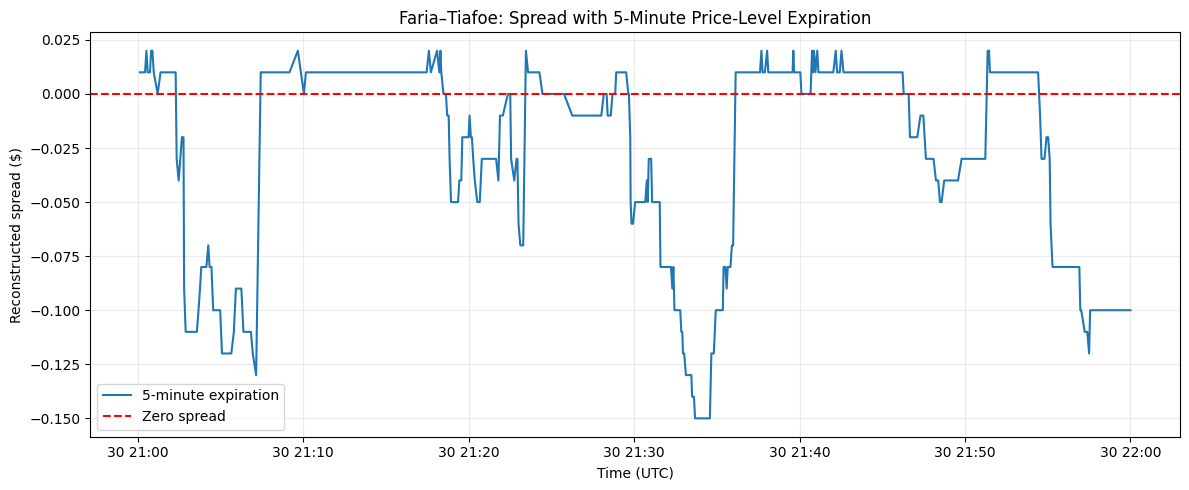

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import heapq

# Experiment settings
MAX_AGE_MINUTES = 5
MAX_AGE_MS = MAX_AGE_MINUTES * 60 * 1000
SAMPLE_EVERY = 1000

# Load one outcome token, preserving physical Parquet row order
updates = con.execute("""
    SELECT
        ts_ms,
        side,
        price,
        size,
        file_row_number
    FROM read_parquet('events.parquet', file_row_number=true)
    WHERE market = ?
      AND asset_id = ?
    ORDER BY file_row_number
""", [top_market, token_id]).df()

# Each price level stores its current size and last update timestamp
book = {"BUY": {}, "SELL": {}}

# Heap entries: (expiration timestamp, side, price, last update timestamp)
expiration_heap = []

history = []
expired_count = 0

for i, row in enumerate(updates.itertuples(index=False), start=1):
    ts = int(row.ts_ms)
    side = row.side
    price = float(row.price)
    size = float(row.size)

    # Expire old price levels efficiently
    while expiration_heap and expiration_heap[0][0] < ts:
        _, old_side, old_price, old_ts = heapq.heappop(expiration_heap)

        current = book[old_side].get(old_price)

        # Only expire if this is still the latest update
        if current is not None and current[1] == old_ts:
            del book[old_side][old_price]
            expired_count += 1

    # Apply the current observation
    if size == 0:
        book[side].pop(price, None)
    else:
        book[side][price] = (size, ts)

        heapq.heappush(
            expiration_heap,
            (ts + MAX_AGE_MS, side, price, ts)
        )

    # Record reconstructed spread
    if i % SAMPLE_EVERY == 0 or i == len(updates):
        best_bid = max(book["BUY"]) if book["BUY"] else np.nan
        best_ask = min(book["SELL"]) if book["SELL"] else np.nan

        spread = (
            best_ask - best_bid
            if np.isfinite(best_bid) and np.isfinite(best_ask)
            else np.nan
        )

        history.append({
            "ts_ms": ts,
            "best_bid": best_bid,
            "best_ask": best_ask,
            "spread": spread,
            "buy_levels": len(book["BUY"]),
            "sell_levels": len(book["SELL"])
        })

expiration_history = pd.DataFrame(history)
expiration_history["time"] = pd.to_datetime(
    expiration_history["ts_ms"], unit="ms", utc=True
)

valid = expiration_history["spread"].dropna()

print(f"Processed observations: {len(updates):,}")
print(f"Expiration threshold: {MAX_AGE_MINUTES} minutes")
print(f"Price-level expirations: {expired_count:,}")
print(f"Valid spread samples: {len(valid):,}")
print(f"Negative spread percentage: {(valid < 0).mean() * 100:.2f}%")
print(f"Final reconstructed spread: {valid.iloc[-1]:.4f}" if len(valid) else "No valid spreads")

# Plot expiration-adjusted spread
plt.figure(figsize=(12, 5))
plt.plot(
    expiration_history["time"],
    expiration_history["spread"],
    linewidth=1.5,
    label="5-minute expiration"
)
plt.axhline(0, color="red", linestyle="--", label="Zero spread")
plt.xlabel("Time (UTC)")
plt.ylabel("Reconstructed spread ($)")
plt.title("Faria–Tiafoe: Spread with 5-Minute Price-Level Expiration")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

,Threshold,Negative spreads (%),Minimum spread ($),Final spread ($),Spread availability (%)
0,5 minutes,50.81,-0.15,-0.10,100.0
1,1 minute,14.78,-0.11,0.01,100.0
2,30 seconds,7.16,-0.06,0.01,100.0


1-minute expirations: 530
30-second expirations: 1,200


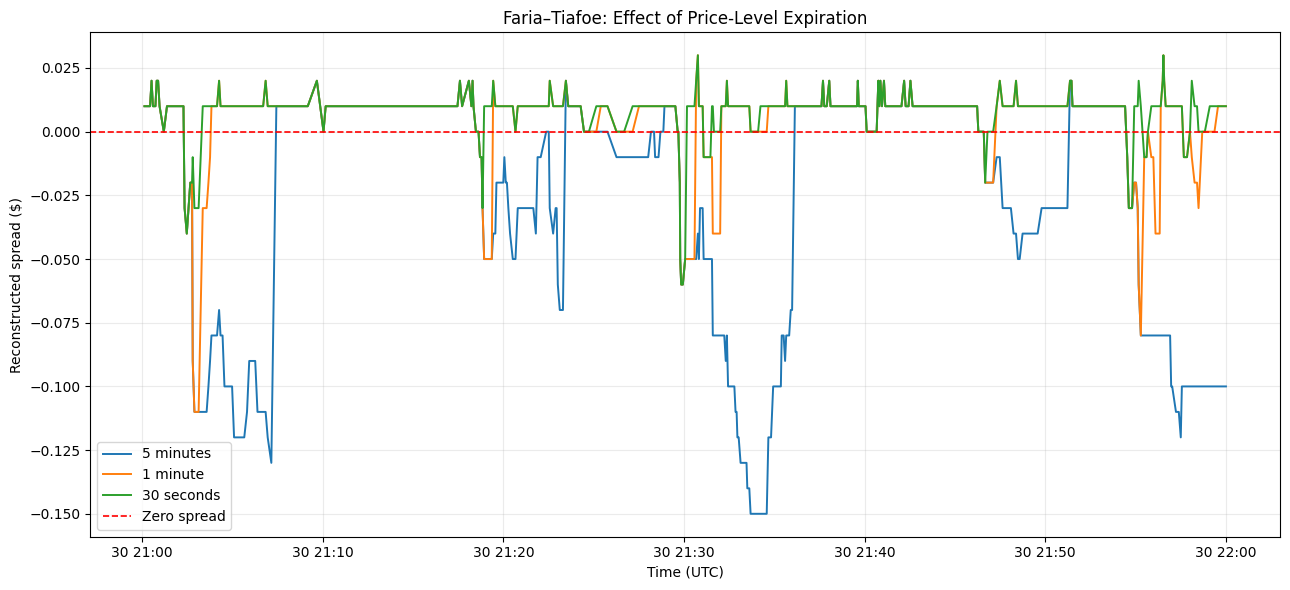

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import heapq

def reconstruct_with_expiration(updates, max_age_seconds, sample_every=1000):
    max_age_ms = max_age_seconds * 1000

    book = {"BUY": {}, "SELL": {}}
    expiration_heap = []
    history = []
    expired_count = 0

    for i, row in enumerate(updates.itertuples(index=False), start=1):
        ts = int(row.ts_ms)
        side = row.side
        price = float(row.price)
        size = float(row.size)

        # Expire price levels older than the threshold
        while expiration_heap and expiration_heap[0][0] < ts:
            _, old_side, old_price, old_ts = heapq.heappop(
                expiration_heap
            )

            current = book[old_side].get(old_price)

            if current is not None and current[1] == old_ts:
                del book[old_side][old_price]
                expired_count += 1

        # Apply the current observation
        if size == 0:
            book[side].pop(price, None)
        else:
            book[side][price] = (size, ts)

            heapq.heappush(
                expiration_heap,
                (ts + max_age_ms, side, price, ts)
            )

        # Record spread at consistent observation intervals
        if i % sample_every == 0 or i == len(updates):
            best_bid = max(book["BUY"]) if book["BUY"] else np.nan
            best_ask = min(book["SELL"]) if book["SELL"] else np.nan

            spread = (
                best_ask - best_bid
                if np.isfinite(best_bid) and np.isfinite(best_ask)
                else np.nan
            )

            history.append({
                "ts_ms": ts,
                "spread": spread,
                "best_bid": best_bid,
                "best_ask": best_ask,
                "buy_levels": len(book["BUY"]),
                "sell_levels": len(book["SELL"])
            })

    result = pd.DataFrame(history)
    result["time"] = pd.to_datetime(
        result["ts_ms"], unit="ms", utc=True
    )

    return result, expired_count


# Run both experiments
history_1min, expired_1min = reconstruct_with_expiration(
    updates, max_age_seconds=60
)

history_30sec, expired_30sec = reconstruct_with_expiration(
    updates, max_age_seconds=30
)

# Reuse existing 5-minute results
experiments = {
    "5 minutes": expiration_history,
    "1 minute": history_1min,
    "30 seconds": history_30sec
}

# Compare results
summary = []

for name, df in experiments.items():
    valid = df["spread"].dropna()

    summary.append({
        "Threshold": name,
        "Negative spreads (%)": round(
            100 * (valid < 0).mean(), 2
        ) if len(valid) else np.nan,
        "Minimum spread ($)": round(
            valid.min(), 3
        ) if len(valid) else np.nan,
        "Final spread ($)": round(
            df["spread"].iloc[-1], 3
        ),
        "Spread availability (%)": round(
            100 * df["spread"].notna().mean(), 2
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

print(f"1-minute expirations: {expired_1min:,}")
print(f"30-second expirations: {expired_30sec:,}")

# Plot all three thresholds
plt.figure(figsize=(13, 6))

for name, df in experiments.items():
    plt.plot(
        df["time"],
        df["spread"],
        label=name,
        linewidth=1.4
    )

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="Zero spread"
)

plt.title("Faria–Tiafoe: Effect of Price-Level Expiration")
plt.xlabel("Time (UTC)")
plt.ylabel("Reconstructed spread ($)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

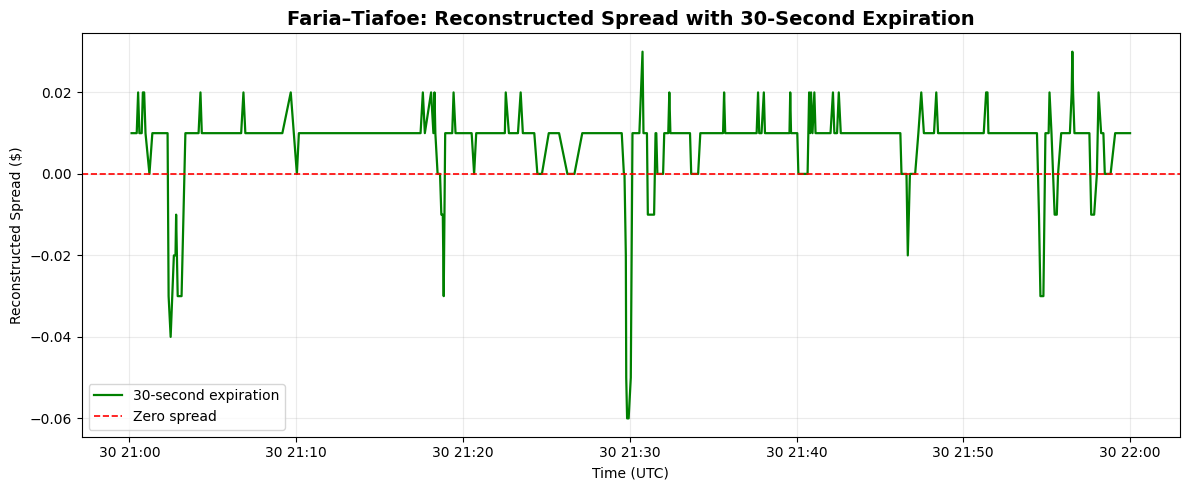

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    history_30sec["time"],
    history_30sec["spread"],
    color="green",
    linewidth=1.6,
    label="30-second expiration"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="Zero spread"
)

plt.title(
    "Faria–Tiafoe: Reconstructed Spread with 30-Second Expiration",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Time (UTC)")
plt.ylabel("Reconstructed Spread ($)")
plt.legend(loc="lower left")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("faria_30sec_expiration.png", dpi=300, bbox_inches="tight")
plt.show()